# Checkpoint 1: First Results and Plan Revision

**Research question:** Among U.S. Craigslist listings in April-May 2021, is the adjusted dollar decline in listing price per additional 10,000 miles smaller for pickups than for sedans, accounting for vehicle age, manufacturer, condition, transmission, and drivetrain?

## 1. Progress Against Proposal

Our proposal committed us to loading and cleaning the pickup/sedan listings, documenting missing and implausible values, creating vehicle-age and 10,000-mile mileage measures, and producing a cleaned dataset and exploratory summaries. We completed these steps for 119,016 listings (40,481 pickups and 78,535 sedans) and exported the cleaned dataset. A fresh download from the proposal's Kaggle source reproduces the original dimensions and group counts; we retain the original question and document the cleaning and missing-data assumptions that need further checks.


## 2. Method Implemented

### Data and workflow

We use the `vehicles.csv` file from Austin Reese's [Used Cars Dataset on Kaggle](https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data), the source linked in our proposal. The source has 426,880 listings and 26 columns; we load the 12 columns needed for analysis, date checks, and listing/vehicle identification. We retain the exact `pickup` and `sedan` categories, giving 130,566 listings before numeric cleaning; the separate `truck` category is outside our stated subset. Non-missing posting dates fall in April-May 2021, and none of the pickup/sedan listings lacks a posting date.

Each observation is one listing, not necessarily one unique vehicle. We check listing URLs and IDs for duplication and separately count repeated non-missing VINs. We retain distinct listings, but repeated vehicles can give some vehicles extra weight and will require a sensitivity check before statistical inference.

### Preprocessing and representation

| Step | Input and rule | Output and reason |
|---|---|---|
| Date and type selection | Raw listings; keep observed dates and exact pickup/sedan labels | Listings in the proposed period and categories |
| Required numeric fields | Exclude missing price, odometer, or model year | Records with observed outcome, mileage, and age inputs |
| Price restriction | Keep $101-$100,000, inclusive | Remove very low placeholder-like prices and extreme prices; some genuine listings may be excluded |
| Mileage restriction | Keep 1-400,000 miles, inclusive | Remove nonpositive readings and extreme mileage while retaining plausible high-mileage vehicles |
| Model-year restriction | Keep 1900-2021, inclusive | Define nonnegative model-year age relative to 2021; 2022 models can exist in 2021 but are outside this age definition |
| Missing categories | Replace missing manufacturer, condition, transmission, and drive with `unknown` | Preserve listings and record missing information explicitly |
| Derived features | Age = 2021 minus model year; mileage = odometer divided by 10,000 | Comparable age and mileage units for the planned model |

The 300,000-mile diagnostic is a flag for inspection, not the exclusion threshold. The final ceiling is 400,000 miles to preserve high-mileage listings relevant to the question; its influence remains to be checked. Pre-1990 vehicles are retained rather than assumed erroneous, but their price relationship may differ from ordinary used vehicles. These are preliminary analytic restrictions, not proof that every retained value is valid or every excluded value is an error. The sequential audit below applies the same final rules and counts each excluded listing once.

The resulting table has 119,016 listings and 11 columns, including the ID. Labeling missing categories `unknown` does not recover their values; we retain this category for later encoding rather than interpolating nominal labels.

### Analysis completed and connection to the question

We calculate counts, missing-value totals, quantiles, and group summaries, then compare listing price, mileage, and age between pickups and sedans. The cleaned listing table is the input; the outputs are a cleaning audit, group comparison table, and exploratory mileage-price figure. These summaries check whether the proposed comparison is feasible and expose distribution differences; they do not estimate the adjusted mileage effect. The multiple linear regression and mileage-by-type interaction remain the next checkpoint's analysis.

### Reproducibility

Run this notebook from the `checkpoint1` directory with the Kaggle file at `data/vehicles.csv` (or `vehicles.csv`). The download source and SHA-256 are recorded in `data/source.json`. The notebook exports the cleaned data and audit locally; raw archives and CSVs are excluded from Git because of their size.

### Supporting workflow


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display


The following cells implement the documented selection and cleaning workflow, with diagnostics retained for review.

In [2]:
data_path = Path("data/vehicles.csv")
if not data_path.exists():
    data_path = Path("vehicles.csv")
if not data_path.exists():
    raise FileNotFoundError("Download vehicles.csv from the linked Kaggle dataset into checkpoint1/data/.")
raw_columns = pd.read_csv(data_path, nrows=0).columns.tolist()
required_columns = ["id", "url", "VIN", "posting_date", "price", "odometer", "year", "manufacturer", "condition", "transmission", "drive", "type"]
df = pd.read_csv(data_path, usecols=required_columns)


The dataset is loaded into `df`.

In [3]:
print("Raw source dimensions:", (len(df), len(raw_columns)))
print("Loaded columns:", df.shape[1])
print("Raw columns:", raw_columns)
display(df.head())
df.dtypes


Raw source dimensions: (426880, 26)
Loaded columns: 12
Raw columns: ['id', 'url', 'region', 'region_url', 'price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'VIN', 'drive', 'size', 'type', 'paint_color', 'image_url', 'description', 'county', 'state', 'lat', 'long', 'posting_date']


,id,url,price,year,manufacturer,condition,odometer,transmission,VIN,drive,type,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


id                int64
url              object
price             int64
year            float64
manufacturer     object
condition        object
odometer        float64
transmission     object
VIN              object
drive            object
type             object
posting_date     object
dtype: object

Inspect source dimensions, column names, and loaded data types before selecting the study subset. Unneeded text and image fields are not loaded into memory.

In [4]:
print("Duplicate URLs:", df["url"].duplicated().sum())
print("Repeated non-missing VIN occurrences:", df["VIN"].dropna().duplicated().sum())
print("Missing VINs:", df["VIN"].isna().sum())


Duplicate URLs: 0
Repeated non-missing VIN occurrences: 147574
Missing VINs: 161042


The saved source has no duplicate listing URLs. VIN identifies a vehicle rather than a listing, and many VINs are missing. We retain distinct listings under the proposal's observation definition and count repeated VINs only after excluding missing values. Repeated vehicles remain a potential source of unequal weighting and dependence.

In [5]:
print(
    df["posting_date"]
    .astype("string")
    .str[:7]
    .value_counts()
    .sort_index()
)

posting_date
2021-04    316969
2021-05    109843
Name: count, dtype: Int64


The non-missing source dates are April-May 2021: 316,969 listings in April and 109,843 in May. This matches the proposal's period.

In [6]:
print(df["posting_date"].isna().sum())

68


Check missing posting dates before applying the period restriction.

In [7]:
print(
    df[df["type"].isin(["pickup", "sedan"])]["posting_date"].isna().sum()
)

0


There are 68 missing posting dates in the source; none belongs to the pickup/sedan subset.

In [8]:
observed_months = set(df["posting_date"].dropna().str[:7].unique())
assert observed_months <= {"2021-04", "2021-05"}, "Source period changed; review the date restriction."
df = df.dropna(subset=["posting_date"])


Records with missing `posting_date` are removed because we are not sure if they were made between April and May 2021. No other date filter is needed because the observed non-missing dates are already April or May 2021.

In [9]:
print(df["posting_date"].isna().sum())

0


The follow-up check confirms that the working dataset has no missing posting dates after the exclusion.

In [10]:
subset_columns = df[["id","price", "odometer", "year", "manufacturer", "condition", "transmission", "drive", "type"]]

Select the listing ID and the eight research variables. Price and odometer are numerical; model year supplies model-year age; manufacturer, condition, transmission, drive, and type are categorical.

In [11]:
subset_type = subset_columns[
    subset_columns["type"].isin(["pickup", "sedan"])
]

Restrict listings to the exact `pickup` and `sedan` labels. The separate `truck` category is excluded to preserve the proposal's category definition.

In [12]:
print("Duplicate IDs:", subset_type["id"].duplicated().sum())

Duplicate IDs: 0


There are no duplicate listing IDs in the selected subset. Matching non-identifier fields alone do not establish duplicate listings, particularly when categorical information is missing.

In [13]:
print(subset_type["type"].value_counts(dropna=False))
print(subset_type.isna().sum())
print(subset_type[["price", "odometer", "year"]].describe())

type
sedan     87056
pickup    43510
Name: count, dtype: int64
id                  0
price               0
odometer         1542
year              578
manufacturer     3011
condition       44092
transmission      599
drive           28275
type                0
dtype: int64
              price      odometer           year
count  1.305660e+05  1.290240e+05  129988.000000
mean   5.887217e+04  8.804216e+04    2012.435240
std    1.081098e+07  1.585760e+05       7.830641
min    0.000000e+00  0.000000e+00    1923.000000
25%    6.350000e+03  3.433750e+04    2010.000000
50%    1.482800e+04  7.761300e+04    2014.000000
75%    2.699800e+04  1.245320e+05    2017.000000
max    3.736929e+09  1.000000e+07    2022.000000


These outputs describe group sizes, missingness, and numeric distributions before cleaning. Zero and extreme values require inspection before analysis.

In [14]:
numeric_cols = ["price", "odometer", "year"]
display(subset_type[numeric_cols].quantile([0, 0.01, 0.05, 0.50, 0.95, 0.99, 0.995, 0.999, 1]))
for column in numeric_cols:
    print(f"\n{column}")
    print(subset_type.nlargest(10, column)[["type", "price", "odometer", "year"]])


,price,odometer,year
0.000,0.000000e+00,0.00,1923.0
0.010,0.000000e+00,129.23,1979.0
0.050,0.000000e+00,8522.15,2001.0
0.500,1.482800e+04,77613.00,2014.0
0.950,4.259000e+04,193236.80,2019.0
0.990,6.299500e+04,254252.00,2020.0
0.995,6.998100e+04,280000.00,2020.0
0.999,8.790000e+04,510065.00,2021.0
1.000,3.736929e+09,10000000.00,2022.0



price
          type       price   odometer    year
318592  pickup  3736928711   164000.0  2007.0
29386   pickup  1111111111   149000.0  1999.0
137807   sedan   123456789    96000.0  1999.0
193736   sedan   123456789    64181.0  2015.0
207080  pickup   123456789  1234567.0  2003.0
307488  pickup   123456789   320000.0  1996.0
136516  pickup    17000000   170000.0  2007.0
327938   sedan     3226714     1234.0  2002.0
68935    sedan     2000000   164290.0  2002.0
208617  pickup      554900    25365.0  2019.0

odometer
          type  price    odometer    year
144436   sedan   4500  10000000.0  2010.0
151740   sedan    800  10000000.0  1949.0
262338  pickup   4800  10000000.0  1949.0
287115   sedan      0  10000000.0  1995.0
292399   sedan   1300  10000000.0  1950.0
305172   sedan   4500  10000000.0  1995.0
27200    sedan   1500   9999999.0  1989.0
217319  pickup   6500   9999999.0  1941.0
217320  pickup   5500   9999999.0  1939.0
219681   sedan    900   9999999.0  1993.0

year
         

Inspect percentiles and large observations before choosing analytic bounds. Billion-dollar prices and odometer readings near 10 million miles indicate data-quality problems; less extreme observations still require judgment.

In [15]:
rules = {
    "nonpositive price": subset_type["price"] <= 0,
    "nonpositive odometer": subset_type["odometer"] <= 0,
    "year after 2021": subset_type["year"] > 2021,
    "year before 1990": subset_type["year"] < 1990,
    "price above 100,000": subset_type["price"] > 100_000,
    "odometer above 300,000": subset_type["odometer"] > 300_000,
}

pd.Series({name: rule.sum() for name, rule in rules.items()})

nonpositive price         8871
nonpositive odometer       397
year after 2021              2
year before 1990          1920
price above 100,000         60
odometer above 300,000     418
dtype: int64

These diagnostic counts overlap and must not be summed as sequential exclusions. Nonpositive includes zero. Mileage above 300,000 and model years before 1990 are inspection flags; the final retained limits are documented separately.

In [16]:
subset_type.duplicated().sum()

np.int64(0)

In [17]:
subset_type.groupby("type")[["price", "odometer", "year"]].quantile(
    [0.01, 0.05, 0.50, 0.95, 0.99, 0.995, 0.999]
)

price    odometer      year
type                                         
pickup 0.010      0.000     102.000  1973.000
       0.050      1.000    7663.050  2000.000
       0.500  27990.000   71288.000  2015.000
       0.950  54466.000  211000.000  2020.000
       0.990  71995.000  274820.000  2020.000
       0.995  78981.000  307085.785  2020.365
       0.999  89900.000  999999.000  2021.000
sedan  0.010      0.000     160.000  1986.000
       0.050      0.000    8973.000  2002.000
       0.500   9995.000   79983.000  2014.000
       0.950  34947.000  184443.750  2019.000
       0.990  44000.000  234205.950  2020.000
       0.995  49995.000  260000.000  2020.000
       0.999  80942.165  400000.000  2021.000

We find quantiles for both pickups and sedans because the two vehicle types can have different price and mileage distributions. The results show that a price ceiling of $100,000 is above the 99.9th percentile for both groups.

In [18]:
subset_type.loc[
    (subset_type["price"] > 100_000) | (subset_type["odometer"] > 300_000),
    ["type", "price", "odometer", "year"]
].sort_values(["price", "odometer"], ascending=False).head(30)

,type,price,odometer,year
318592,pickup,3736928711,164000.0,2007.0
29386,pickup,1111111111,149000.0,1999.0
207080,pickup,123456789,1234567.0,2003.0
307488,pickup,123456789,320000.0,1996.0
137807,sedan,123456789,96000.0,1999.0
193736,sedan,123456789,64181.0,2015.0
136516,pickup,17000000,170000.0,2007.0
327938,sedan,3226714,1234.0,2002.0
68935,sedan,2000000,164290.0,2002.0
208617,pickup,554900,25365.0,2019.0


In [19]:
cleaned = subset_type.copy()

cleaned = cleaned.loc[
    cleaned["price"].between(101, 100_000)
    & cleaned["odometer"].between(1, 400_000)
    & cleaned["year"].between(1900, 2021)
].copy()

categorical_cols = ["manufacturer", "condition", "transmission", "drive"]
cleaned[categorical_cols] = cleaned[categorical_cols].fillna("unknown")

cleaned["vehicle_age"] = 2021 - cleaned["year"]
cleaned["odometer_10k"] = cleaned["odometer"] / 10_000

### Final cleaning decisions

Apply the inclusive bounds stated in Section 2. Missing required numerical values fail these bounds and are excluded. Missing categorical values have already been replaced with `unknown`; no interpolation is planned. The 2021 reference year gives model-year age, and each unit of `odometer_10k` represents 10,000 miles.

In [20]:
print(cleaned.shape)
print(cleaned.isna().sum())
print(cleaned["type"].value_counts())
print(cleaned[["price", "odometer", "vehicle_age", "odometer_10k"]].describe())

cleaned.groupby("type")[["price", "odometer", "vehicle_age", "odometer_10k"]].describe()

(119016, 11)
id              0
price           0
odometer        0
year            0
manufacturer    0
condition       0
transmission    0
drive           0
type            0
vehicle_age     0
odometer_10k    0
dtype: int64
type
sedan     78535
pickup    40481
Name: count, dtype: int64
               price       odometer    vehicle_age   odometer_10k
count  119016.000000  119016.000000  119016.000000  119016.000000
mean    19059.832502   85900.689277       8.667793       8.590069
std     13796.877490   60119.054091       7.876928       6.011905
min       101.000000       1.000000       0.000000       0.000100
25%      7800.000000   34375.000000       4.000000       3.437500
50%     15995.000000   78781.000000       7.000000       7.878100
75%     27990.000000  125957.000000      11.000000      12.595700
max     99999.000000  400000.000000      98.000000      40.000000


price                                                                \
          count          mean           std    min      25%      50%      75%   
type                                                                            
pickup  40481.0  28496.301598  14369.891345  123.0  18995.0  27995.0  35995.0   
sedan   78535.0  14195.788375  10605.553952  101.0   6000.0  10999.0  19990.0   

                odometer                ... vehicle_age       odometer_10k  \
            max    count          mean  ...         75%   max        count   
type                                    ...                                  
pickup  99999.0  40481.0  85517.186384  ...        10.0  98.0      40481.0   
sedan   99950.0  78535.0  86098.366499  ...        12.0  97.0      78535.0   

                                                                 
            mean       std     min     25%     50%    75%   max  
type                                                             
pickup  8.551719  6.729232  0.0001  2.7715  7.0559  13.20  40.0  
sedan   8.609837  5.606369  0.0001  3.8867  8.1675  12.37  40.0  

[2 rows x 32 columns]

The saved validation output contains 119,016 listings: 40,481 pickups and 78,535 sedans. There are 11 columns, including the listing ID and the two derived features. Missing categorical values have been labeled `unknown`; this does not recover the original information.

In [21]:
lower_tail = {
    "price <= $100": (cleaned["price"] <= 100).sum(),
    "price <= $500": (cleaned["price"] <= 500).sum(),
    "odometer <= 100": (cleaned["odometer"] <= 100).sum(),
    "odometer <= 500": (cleaned["odometer"] <= 500).sum(),
}
display(pd.Series(lower_tail, name="listings"))
cleaned.loc[
    (cleaned["price"] <= 500) | (cleaned["odometer"] <= 100),
    ["type", "price", "odometer", "year", "manufacturer", "condition"]
].head(30)


price <= $100         0
price <= $500      1786
odometer <= 100     606
odometer <= 500    1098
Name: listings, dtype: int64

,type,price,odometer,year,manufacturer,condition
1069,sedan,300,265000.0,1999.0,saturn,fair
2456,pickup,38615,1.0,2021.0,chevrolet,unknown
3501,pickup,38615,1.0,2021.0,chevrolet,unknown
6060,sedan,11992,1.0,2015.0,dodge,unknown
6065,sedan,34999,12.0,2019.0,mini,unknown
6331,sedan,11992,1.0,2015.0,dodge,unknown
6659,sedan,34499,53.0,2019.0,mini,unknown
6693,sedan,11992,1.0,2015.0,dodge,unknown
7042,sedan,34999,12.0,2019.0,mini,unknown
7107,sedan,11992,1.0,2015.0,dodge,unknown


The retained lower tail includes 1,786 prices at or below $500 and 606 odometer readings at or below 100 miles. Some low-mileage listings may be legitimate, but older one-mile readings and very low recent-model prices may be placeholders or payment amounts. We retain them provisionally and will inspect them and compare alternative restrictions. Listings labeled new also require checking against the proposal's used-vehicle scope.

In [22]:
print(pd.Series(lower_tail))

price <= $100         0
price <= $500      1786
odometer <= 100     606
odometer <= 500    1098
dtype: int64


In [23]:
cleaned.to_csv("craigslist_pickup_sedan_cleaned.csv", index=False)
assert len(cleaned) == cleaned["id"].nunique()
assert cleaned[["price", "odometer", "year"]].notna().all().all()
print("Exported cleaned listings:", len(cleaned))


Exported cleaned listings: 119016


The analytic dataset is exported without the pandas index. It supplies the same observations for the next checkpoint's exploratory checks and adjusted price model.

In [24]:
remaining = subset_type.copy()
audit_rows = []
steps = [
    ("Missing required numeric values", lambda x: x[["price", "odometer", "year"]].notna().all(axis=1)),
    ("Price outside $101-$100,000", lambda x: x["price"].between(101, 100_000)),
    ("Odometer outside 1-400,000 miles", lambda x: x["odometer"].between(1, 400_000)),
    ("Model year outside 1900-2021", lambda x: x["year"].between(1900, 2021)),
]
for label, keep_rule in steps:
    before = len(remaining)
    remaining = remaining.loc[keep_rule(remaining)]
    audit_rows.append({"step": label, "removed": before - len(remaining), "remaining": len(remaining)})
cleaning_audit = pd.DataFrame(audit_rows)
assert remaining.index.equals(cleaned.index)
assert cleaning_audit["removed"].sum() == len(subset_type) - len(cleaned)
cleaning_audit.to_csv("cleaning_audit.csv", index=False)
display(cleaning_audit)


,step,removed,remaining
0,Missing required numeric values,2120,128446
1,"Price outside $101-$100,000",8987,119459
2,"Odometer outside 1-400,000 miles",443,119016
3,Model year outside 1900-2021,0,119016


### Sequential cleaning audit

| Exclusion step, in order | Removed at this step | Remaining |
|---|---:|---:|
| Missing required numeric values | 2,120 | 128,446 |
| Price outside $101-$100,000 | 8,987 | 119,459 |
| Odometer outside 1-400,000 miles | 443 | 119,016 |
| Model year outside 1900-2021 | 0 | 119,016 |

Starting subset: 130,566 listings. Total removed: 11,550. Counts depend on the displayed order and do not overlap; a zero in the final row means no additional records fail that rule after earlier exclusions.


## 3. Preliminary Results

### Group comparison

| Measure | Pickups | Sedans |
|---|---:|---:|
| Before numeric cleaning | 43,510 | 87,056 |
| After numeric cleaning | 40,481 | 78,535 |
| Excluded by numeric cleaning | 3,029 (6.96%) | 8,521 (9.79%) |
| Median listing price | $27,995 | $10,999 |
| Mean mileage | 85,517 miles | 86,098 miles |
| Median mileage | 70,559 miles | 81,675 miles |
| Median model-year age | 6 years | 7 years |

The group comparison is computed from the verified Kaggle source. Numeric cleaning retains 119,016 of 130,566 pickup/sedan listings, removing 11,550 (8.85%). The sequential audit records each exclusion once rather than summing overlapping diagnostic flags.

Pickups have a much higher median listing price. Mean mileage is similar between the groups, but the median pickup has 11,116 fewer miles and is one model year younger. These differences make separate group summaries useful and motivate accounting for age and other characteristics before comparing mileage slopes. Higher pickup prices alone do not show that their prices decline less per 10,000 miles.

### Exploratory price-mileage comparison

Figure 1 displays price against mileage in units of 10,000 miles, with the same axes for both groups. A reproducible sample of 3,500 listings per group keeps the points readable; the overlaid medians use all retained listings in 20,000-mile bins with at least 30 observations. These are unadjusted descriptive summaries, not fitted regression effects.


In [25]:
group_summary = cleaned.groupby("type").agg(
    listings=("id", "size"),
    median_price=("price", "median"),
    mean_mileage=("odometer", "mean"),
    median_mileage=("odometer", "median"),
    median_age=("vehicle_age", "median"),
)
group_summary["before_cleaning"] = subset_type.groupby("type").size()
group_summary["removed"] = group_summary["before_cleaning"] - group_summary["listings"]
group_summary["removed_percent"] = 100 * group_summary["removed"] / group_summary["before_cleaning"]
group_summary.to_csv("group_summary.csv")
assert int(group_summary["listings"].sum()) == len(cleaned)
display(group_summary.round(2))


,listings,median_price,mean_mileage,median_mileage,median_age,before_cleaning,removed,removed_percent
type,,,,,,,,
pickup,40481,27995.0,85517.19,70559.0,6.0,43510,3029,6.96
sedan,78535,10999.0,86098.37,81675.0,7.0,87056,8521,9.79


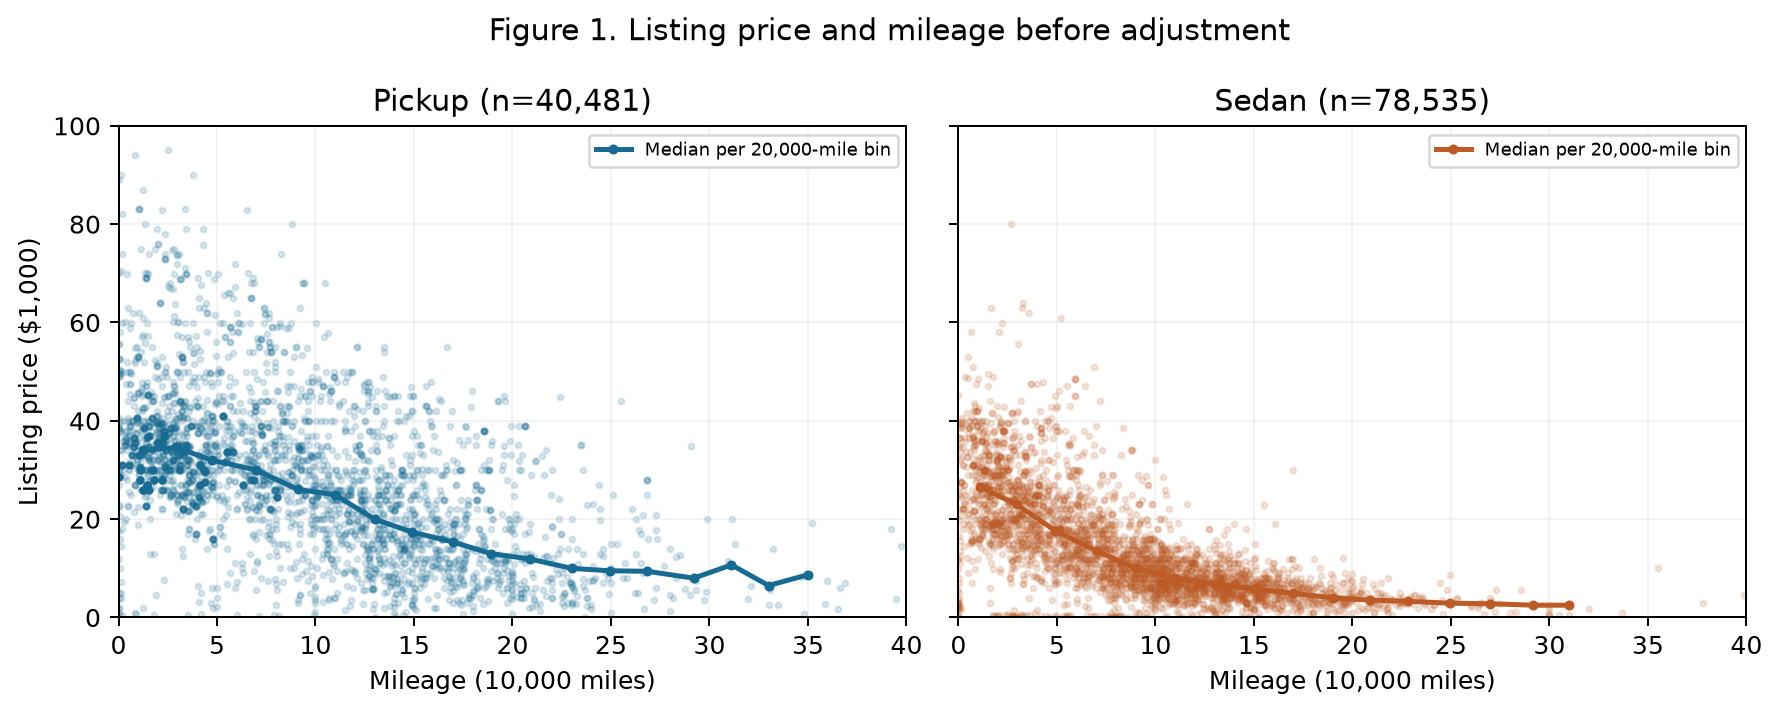

In [26]:
from IPython.display import Image

figure_dir = Path("figures")
figure_dir.mkdir(exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
colors = {"pickup": "#176b92", "sedan": "#bc5b26"}
for ax, vehicle_type in zip(axes, ["pickup", "sedan"]):
    group = cleaned.loc[cleaned["type"].eq(vehicle_type)]
    points = group.sample(n=min(3500, len(group)), random_state=5593)
    ax.scatter(points["odometer_10k"], points["price"] / 1000,
               s=5, alpha=0.15, color=colors[vehicle_type], rasterized=True)
    binned = group.assign(mileage_bin=pd.cut(group["odometer_10k"], np.arange(0, 42, 2), include_lowest=True))
    medians = binned.groupby("mileage_bin", observed=True).agg(
        miles=("odometer_10k", "median"), price=("price", "median"), n=("id", "size"))
    medians = medians.loc[medians["n"].ge(30)]
    ax.plot(medians["miles"], medians["price"] / 1000, color=colors[vehicle_type],
            marker="o", markersize=3, linewidth=2, label="Median per 20,000-mile bin")
    ax.set(title=f"{vehicle_type.title()} (n={len(group):,})", xlabel="Mileage (10,000 miles)", xlim=(0, 40), ylim=(0, 100))
    ax.grid(alpha=0.15)
    ax.legend(fontsize=7, loc="upper right")
axes[0].set_ylabel("Listing price ($1,000)")
fig.suptitle("Figure 1. Listing price and mileage before adjustment", fontsize=12)
fig.tight_layout()
fig.savefig(figure_dir / "price_mileage.png", dpi=180, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(figure_dir / "price_mileage.png")))


Across most mileage bins, median listing prices decrease for both vehicle types, while pickups remain more expensive. The curves flatten at higher mileage and the pickup tail is uneven, so a single constant dollar decline may be an approximation. These exploratory relationships motivate the proposed adjusted comparison, but neither the raw curves nor the price gap establishes that pickups have a smaller adjusted decline per 10,000 miles.


### Limitations and uncertainty

Before numeric cleaning, condition is missing for 44,092 listings (33.77%) and drive for 28,275 (21.66%). An `unknown` category preserves listings but cannot fully account for the missing characteristics. The retained data also include 1,786 prices at or below $500, 606 mileage readings at or below 100 miles, and vehicles up to 98 model years old. These may include unusual genuine listings and reporting errors, so our numeric bounds do not guarantee a homogeneous used-vehicle sample.

Cleaning excludes 9.79% of sedans versus 6.96% of pickups. This difference does not establish bias, but it requires checking whether the comparison depends on filtering choices. Repeated vehicles across distinct listings may also affect weighting and uncertainty. Our evidence concerns asking prices on Craigslist in the specified period, not completed sale prices or the same vehicle losing value over time.

**Course connection:** The group table uses the descriptive statistics and quantiles in the Week 1 reading (pp. 15-23); the figure follows its scatterplot discussion (p. 29). We interpret unusual values as observations to investigate rather than automatically treating every extreme as an error, following Week 1_3 (p. 7).


## 4. Evaluation of the Original Hypothesis and Plan

Our hypothesis remains unresolved: we have not yet estimated the adjusted difference in dollar decline per 10,000 miles. The broad downward price-mileage patterns are consistent with the expectation that higher-mileage listings tend to have lower prices, but they do not establish the predicted smaller decline for pickups. The higher pickup price level is a different quantity from the mileage slope.

The proposal's first steps remain useful. Both groups retain large samples, the required numeric measures can be constructed, and the observed price, mileage, and age differences justify retaining the proposed adjustment for vehicle characteristics. We therefore preserve the original research question and use the mileage-by-type regression as the next comparison.

The data challenge several simplifying assumptions. Missing condition and drive information limits adjustment; suspicious retained prices and odometer readings require inspection; and differential exclusions and repeated vehicles may affect the comparison. We also need to define how listings marked new and very old vehicles fit the used-vehicle population. The curved binned patterns suggest checking whether a single linear mileage slope and linear age adjustment adequately describe the data rather than assuming they do.

These findings call for refining validation and interpretation, not declaring the hypothesis confirmed or rejected. Following Week 1_3 (pp. 3-8), we distinguish the Craigslist sample from the broader vehicle market, consider selection and confounding, and treat the observed patterns as associations rather than causal depreciation.


## 5. Next-Step Plan or Revision

We will continue the original research question and planned interaction regression, while refining the data checks and verifying that the model represents the observed relationships.

1. **Review questionable listings and define the analytic population.** Inspect low-price and near-zero-mileage records, listings marked new, and very old vehicles. Document which are usable for the stated used-vehicle question. Compare the primary analysis with reasonable alternative restrictions and with repeated known-VIN listings reduced to one listing per vehicle, reporting the remaining limitation for missing VINs. This follows from the retained anomalies and unequal cleaning losses.

2. **Prepare the proposed adjusted comparison.** Encode manufacturer, condition, transmission, and drive as categorical indicators, retaining `unknown` explicitly. Fit listing price in dollars using mileage in 10,000-mile units, pickup/sedan type, their interaction, vehicle age, and the four categorical controls. Use sedan as the reference group. The mileage coefficient estimates the sedan slope; adding the interaction gives the pickup slope. A positive interaction supports a smaller pickup decline only when the estimated slopes describe declines and the uncertainty supports the difference.

3. **Check interpretation and model adequacy.** Examine residual patterns and whether age and mileage need more flexible representations, because the exploratory curves are not straight. Compare conclusions across the documented data restrictions and report both slopes, their difference, and confidence intervals using uncertainty estimates that account for unequal residual variation and repeated vehicles where identifiable. Do not treat statistical significance alone as practical importance.

The next artifacts will be a documented sensitivity comparison, the two adjusted dollar changes per 10,000 miles and their difference with uncertainty, and a grouped mileage-price visualization with clearly labeled adjusted predictions. These outputs directly address the proposed hypothesis while preserving the distinction between listing-price association and causal depreciation.


### Sources and verification

**Dataset:** Austin Reese, Used Cars Dataset, Kaggle: https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data. Downloaded October 16, 2026; file checksum and download details are recorded in `data/source.json`.

**Project requirements:** Team Research Proposal, Checkpoint 1 commitment; CS 5593 Team Project: Checkpoint 1, First Results and Plan Revision, pp. 1-2.

**Course material:** Week 1 reading, pp. 15-23 and 29 (descriptive statistics, quantiles, and scatterplots); Week 1_3, pp. 3-8 (sample selection, association, confounding, unusual observations, and analytical validity).

**Verification:** The downloaded source reproduces 426,880 rows, 26 columns, April-May posting counts, 130,566 pickup/sedan listings before numeric cleaning, and 119,016 after cleaning. All 26 code cells executed successfully; the exported group summary, cleaning audit, and figure come from that execution. No adjusted regression result is claimed at this checkpoint.


---
# Checkpoint 2: Extended Analysis and Model Evaluation

**Continuation of Checkpoint 1.** All earlier cells, cleaning decisions, summaries, and outputs are retained above. This section examines the adjusted mileage effect, its statistical uncertainty, the assumptions behind inference, and whether the result changes under different data and modeling choices. Each analysis saves a table or figure for the Checkpoint 2 report.

**Run order:** Run Checkpoint 1 first, then these cells. Checkpoint 1 requires `data/vehicles.csv` or `vehicles.csv`. The final cell packages the new outputs into `checkpoint2_outputs.zip`.

## 1. Progress against the plan

Checkpoint 1 established the analytic sample but did not estimate adjusted mileage slopes. We retain the original question and examine the three unresolved issues identified there: distributional anomalies, missing or repeated vehicle information, and whether a single linear mileage slope adequately represents the data.

In [27]:
from pathlib import Path
import json
import sys
import warnings
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from IPython.display import display

CP2_OUT = Path('checkpoint2_outputs')
CP2_TABLES = CP2_OUT / 'tables'
CP2_FIGS = CP2_OUT / 'figures'
CP2_TABLES.mkdir(parents=True, exist_ok=True)
CP2_FIGS.mkdir(parents=True, exist_ok=True)
CP2_SEED = 5593
CP2_COLORS = {'pickup': '#176b92', 'sedan': '#bc5b26'}

def save_table(frame, filename, show=12):
    path = CP2_TABLES / filename
    frame.to_csv(path, index=False)
    print('Saved:', path)
    display(frame.head(show))
    return frame

def save_figure(fig, filename):
    path = CP2_FIGS / filename
    fig.savefig(path, dpi=170, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved:', path)
    return path

def fmt_p(value):
    if not np.isfinite(value):
        return 'not available'
    return '< 0.0001' if value < 0.0001 else f'{value:.4f}'

print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('Checkpoint 2 outputs:', CP2_OUT.resolve())

Python: 3.11.6 | pandas: 2.3.3
Checkpoint 2 outputs: C:\Users\masiko\Downloads\Data Mining\checkpoint2_outputs


## 2. Method implemented or refined

### 2.1 Verify the study population and recover VIN information

The unit of analysis remains the **listing**. `cleaned` is the exact Checkpoint 1 output; the original data table, if available, supplies VINs for dependence and duplicate-vehicle checks. Missing or invalid VINs cannot establish vehicle independence.

In [28]:
if 'cleaned' not in globals():
    cp1_csv = Path('craigslist_pickup_sedan_cleaned.csv')
    if not cp1_csv.exists():
        raise RuntimeError('Run the Checkpoint 1 cells first. The cleaned DataFrame/CSV is not available.')
    cleaned = pd.read_csv(cp1_csv)

cp2 = cleaned.copy().reset_index(drop=True)
expected = {'id','type','price','odometer','year','vehicle_age','odometer_10k',
            'manufacturer','condition','transmission','drive'}
missing = expected.difference(cp2.columns)
assert not missing, f'Missing Checkpoint 1 columns: {sorted(missing)}'
assert set(cp2['type']) == {'pickup','sedan'}
assert cp2['id'].is_unique, 'Listing IDs are not unique; review Checkpoint 1 selection.'
assert cp2[['price','odometer','year','vehicle_age','odometer_10k']].notna().all().all()
assert cp2['price'].between(101,100_000).all()
assert cp2['odometer'].between(1,400_000).all()
assert cp2['year'].between(1900,2021).all()
assert np.allclose(cp2['odometer_10k'], cp2['odometer']/10_000)
assert np.allclose(cp2['vehicle_age'], 2021-cp2['year'])
cp2['is_pickup'] = cp2['type'].eq('pickup').astype(int)
cp2['mileage_x_pickup'] = cp2['odometer_10k'] * cp2['is_pickup']

# The CP1 `df` still has the VIN, even though the exported cleaned table does not.
if 'df' in globals() and {'id','VIN'}.issubset(df.columns):
    vin_lookup = df[['id','VIN']].drop_duplicates('id')
    cp2 = cp2.merge(vin_lookup, on='id', how='left', validate='one_to_one')
elif 'VIN' not in cp2:
    original = Path('data/vehicles.csv') if Path('data/vehicles.csv').exists() else Path('vehicles.csv')
    if original.exists():
        vin_lookup = pd.read_csv(original, usecols=['id','VIN']).drop_duplicates('id')
        cp2 = cp2.merge(vin_lookup, on='id', how='left', validate='one_to_one')
    else:
        cp2['VIN'] = pd.NA

# Only plausible 17-character vehicle identifiers are considered known VINs.
vin_str = cp2['VIN'].astype('string').str.strip().str.upper()
valid_vin = vin_str.str.fullmatch(r'[A-HJ-NPR-Z0-9]{17}').fillna(False)
cp2['vin_key'] = vin_str.where(valid_vin, pd.NA)
cp2['vehicle_cluster'] = np.where(cp2['vin_key'].notna(),
                                   'VIN:' + cp2['vin_key'].fillna('').astype(str),
                                   'LISTING:' + cp2['id'].astype(str))
cp2['known_vin_repeated'] = cp2['vin_key'].notna() & cp2['vin_key'].duplicated(keep=False)

integrity = pd.DataFrame([
    {'measure':'Listings', 'value':int(len(cp2))},
    {'measure':'Pickups', 'value':int(cp2['is_pickup'].sum())},
    {'measure':'Sedans', 'value':int((1-cp2['is_pickup']).sum())},
    {'measure':'Unique listing IDs', 'value':int(cp2['id'].nunique())},
    {'measure':'Listings with plausible VIN', 'value':int(cp2['vin_key'].notna().sum())},
    {'measure':'Listings in repeated known-VIN groups', 'value':int(cp2['known_vin_repeated'].sum())},
    {'measure':'Repeated known VINs (distinct identifiers)',
     'value':int(cp2.loc[cp2['known_vin_repeated'],'vin_key'].nunique())},
    {'measure':'Vehicle clusters used for grouped splits', 'value':int(cp2['vehicle_cluster'].nunique())}
])
save_table(integrity, '01_sample_integrity.csv')
if len(cp2) != 119_016:
    print('NOTE: sample size differs from the documented Checkpoint 1 total of 119,016. Verify input.')

Saved: checkpoint2_outputs\tables\01_sample_integrity.csv


,measure,value
0,Listings,119016
1,Pickups,40481
2,Sedans,78535
3,Unique listing IDs,119016
4,Listings with plausible VIN,85244
5,Listings in repeated known-VIN groups,63100
6,Repeated known VINs (distinct identifiers),12426
7,Vehicle clusters used for grouped splits,68342


### 2.2 Distribution and missing-information audit

Describe the **observed distributions** rather than assuming normality. Compare median, mean, spread, tails, and skewness separately by type. A skewed price distribution does **not** by itself invalidate OLS; residual behavior and the regression assumptions matter for inference. The figures use the full sample for statistics and clearly labeled percentile limits only for display.

In [29]:
dist_rows=[]
for kind, part in cp2.groupby('type'):
    for col, unit in [('price','USD'),('odometer','miles'),('vehicle_age','years')]:
        x=part[col].astype(float)
        dist_rows.append({
            'type':kind,'variable':col,'unit':unit,'n':len(x),
            'mean':x.mean(),'sd':x.std(),'median':x.median(),
            'p01':x.quantile(.01),'p05':x.quantile(.05),'q1':x.quantile(.25),
            'q3':x.quantile(.75),'p95':x.quantile(.95),'p99':x.quantile(.99),
            'max':x.max(),'iqr':x.quantile(.75)-x.quantile(.25),
            'skewness':stats.skew(x,bias=False),
            'mean_to_median':x.mean()/x.median() if x.median() != 0 else np.nan
        })
dist_table=pd.DataFrame(dist_rows)
save_table(dist_table.round(3), '02_distribution_by_type.csv')

flags={
    'price <= $500':cp2['price'].le(500),
    'odometer <= 100 miles':cp2['odometer'].le(100),
    'odometer > 300,000 miles':cp2['odometer'].gt(300_000),
    'vehicle age > 30 years':cp2['vehicle_age'].gt(30),
    'condition marked new':cp2['condition'].astype(str).str.lower().eq('new'),
    'condition unknown':cp2['condition'].eq('unknown'),
    'drive unknown':cp2['drive'].eq('unknown'),
    'manufacturer unknown':cp2['manufacturer'].eq('unknown'),
    'transmission unknown':cp2['transmission'].eq('unknown'),
    'repeated known VIN':cp2['known_vin_repeated']
}
flag_rows=[]
for label, mask in flags.items():
    for kind, part in cp2.groupby('type'):
        n=int(mask.loc[part.index].sum())
        flag_rows.append({'flag':label,'type':kind,'count':n,'share_pct':100*n/len(part)})
flag_table=pd.DataFrame(flag_rows)
save_table(flag_table.round(3), '03_quality_flags_by_type.csv',show=25)

Saved: checkpoint2_outputs\tables\02_distribution_by_type.csv


,type,variable,unit,n,mean,sd,median,p01,p05,q1,q3,p95,p99,max,iqr,skewness,mean_to_median
0,pickup,price,USD,40481,28496.302,14369.891,27995.0,1800.00,5500.0,18995.0,35995.0,53995.0,69997.4,99999.0,17000.0,0.562,1.018
1,pickup,odometer,miles,40481,85517.186,67292.316,70559.0,458.00,8218.0,27715.0,132000.0,209977.0,269978.4,400000.0,104285.0,0.869,1.212
2,pickup,vehicle_age,years,40481,8.376,8.411,6.0,1.00,1.0,3.0,10.0,21.0,47.0,98.0,7.0,3.590,1.396
3,sedan,price,USD,78535,14195.788,10605.554,10999.0,251.00,2000.0,6000.0,19990.0,34998.0,43990.0,99950.0,13990.0,1.257,1.291
4,sedan,odometer,miles,78535,86098.366,56063.694,81675.0,792.68,9345.0,38867.0,123700.0,185749.0,233105.0,400000.0,84833.0,0.612,1.054
5,sedan,vehicle_age,years,78535,8.818,7.582,7.0,1.00,2.0,4.0,12.0,19.0,36.0,97.0,8.0,4.260,1.260


Saved: checkpoint2_outputs\tables\03_quality_flags_by_type.csv


,flag,type,count,share_pct
0,price <= $500,pickup,133,0.329
1,price <= $500,sedan,1653,2.105
2,odometer <= 100 miles,pickup,174,0.430
3,odometer <= 100 miles,sedan,432,0.550
4,"odometer > 300,000 miles",pickup,163,0.403
5,"odometer > 300,000 miles",sedan,96,0.122
6,vehicle age > 30 years,pickup,904,2.233
7,vehicle age > 30 years,sedan,971,1.236
8,condition marked new,pickup,62,0.153
9,condition marked new,sedan,153,0.195


,flag,type,count,share_pct
0,price <= $500,pickup,133,0.329
1,price <= $500,sedan,1653,2.105
2,odometer <= 100 miles,pickup,174,0.430
3,odometer <= 100 miles,sedan,432,0.550
4,"odometer > 300,000 miles",pickup,163,0.403
5,"odometer > 300,000 miles",sedan,96,0.122
6,vehicle age > 30 years,pickup,904,2.233
7,vehicle age > 30 years,sedan,971,1.236
8,condition marked new,pickup,62,0.153
9,condition marked new,sedan,153,0.195


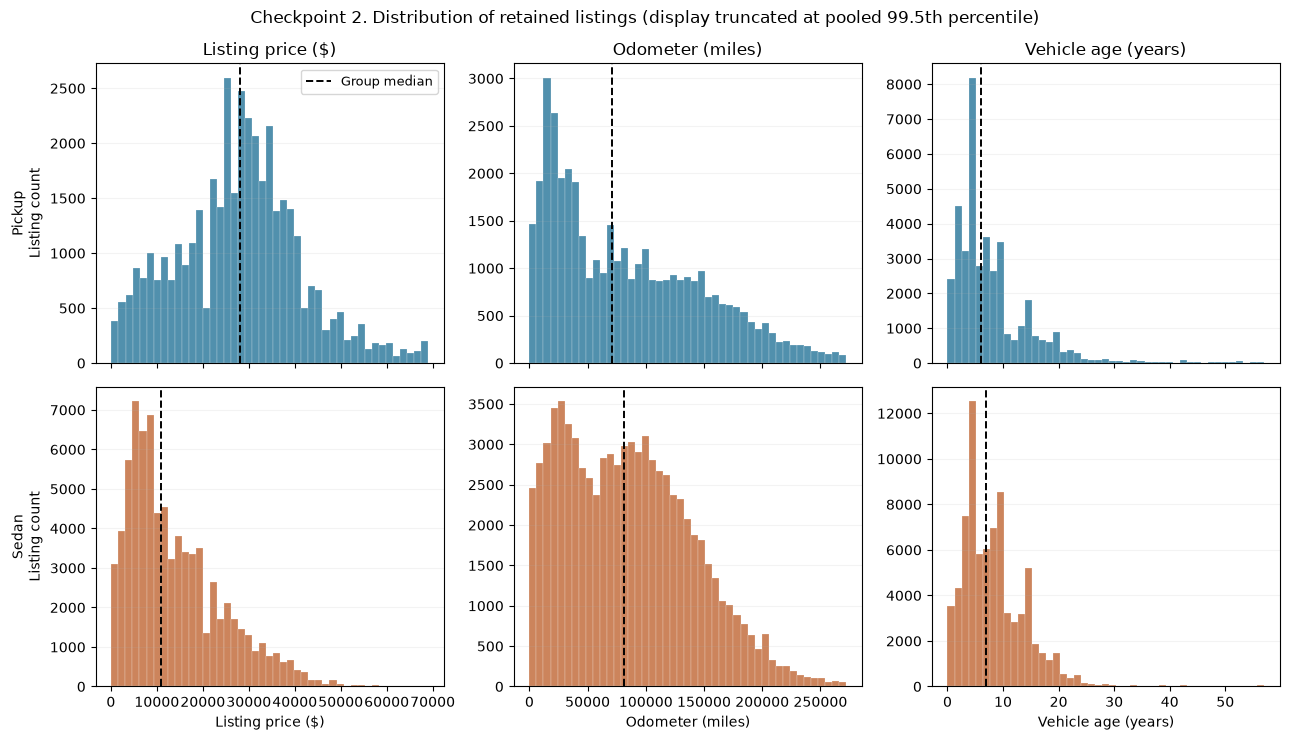

Saved: checkpoint2_outputs\figures\01_distributions.png


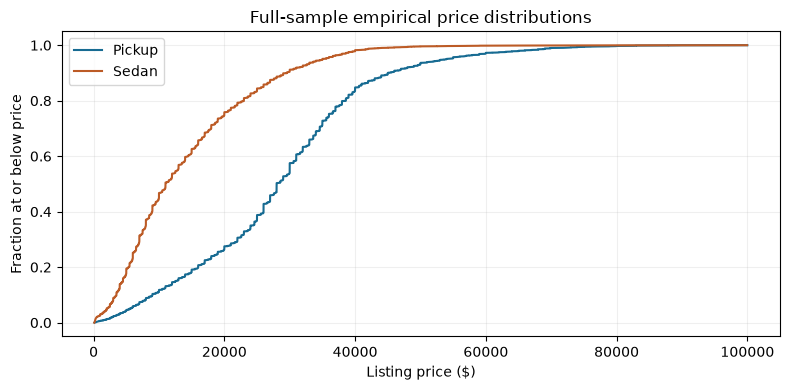

Saved: checkpoint2_outputs\figures\02_price_ecdf.png


WindowsPath('checkpoint2_outputs/figures/02_price_ecdf.png')

In [30]:
fig, axes=plt.subplots(2,3,figsize=(13,7.5),sharex='col')
for row,kind in enumerate(['pickup','sedan']):
    part=cp2[cp2['type'].eq(kind)]
    for j,(col,title) in enumerate([('price','Listing price ($)'),('odometer','Odometer (miles)'),
                                     ('vehicle_age','Vehicle age (years)')]):
        ax=axes[row,j]
        upper=cp2[col].quantile(.995)
        observed=part[col].loc[part[col].le(upper)]
        ax.hist(observed,bins=45,color=CP2_COLORS[kind],alpha=.75,edgecolor='white',lw=.2)
        ax.axvline(part[col].median(),ls='--',lw=1.4,color='black',label='Group median')
        if row==0: ax.set_title(title)
        if j==0: ax.set_ylabel(f'{kind.title()}\nListing count')
        if row==1: ax.set_xlabel(title)
        ax.grid(alpha=.15,axis='y')
        if row==0 and j==0: ax.legend(fontsize=9)
fig.suptitle('Checkpoint 2. Distribution of retained listings (display truncated at pooled 99.5th percentile)')
fig.tight_layout()
save_figure(fig,'01_distributions.png')

fig, ax=plt.subplots(figsize=(8,4))
for kind in ['pickup','sedan']:
    x=np.sort(cp2.loc[cp2['type'].eq(kind),'price'].values)
    y=np.arange(1,len(x)+1)/len(x)
    ax.plot(x,y,label=kind.title(),color=CP2_COLORS[kind],lw=1.5)
ax.set(xlabel='Listing price ($)',ylabel='Fraction at or below price',
       title='Full-sample empirical price distributions')
ax.legend()
ax.grid(alpha=.2)
fig.tight_layout()
save_figure(fig,'02_price_ecdf.png')

### 2.3 Representation and identification of the mileage effect

Use numerical mileage (per 10,000 miles), age, a pickup indicator, and **mileage × pickup**. Encode manufacturer, condition, transmission, and drivetrain as categorical indicators. Combine very rare levels (fewer than 30 listings) to avoid unstable near-singleton fixed effects; retain `unknown` as its own level. The original `cleaned` table is not altered.

In [31]:
CATS=['manufacturer','condition','transmission','drive']
CATS_MODEL=[f'{c}_model' for c in CATS]
rare_rows=[]
for raw_col,model_col in zip(CATS,CATS_MODEL):
    s=cp2[raw_col].fillna('unknown').astype(str)
    counts=s.value_counts()
    rare=counts[counts<30].index.difference(pd.Index(['unknown']))
    cp2[model_col]=s.where(~s.isin(rare),'other_rare')
    for value,count in counts.items():
        rare_rows.append({'feature':raw_col,'original_level':value,'count':int(count),
                          'used_level':'other_rare' if value in rare else value,
                          'rare_level_combined':bool(value in rare)})
rare_table=pd.DataFrame(rare_rows)
save_table(rare_table,'04_categorical_encoding_audit.csv',show=18)
print('Levels after encoding:',{name:cp2[name].nunique() for name in CATS_MODEL})

CONTROL_TERMS=' + '.join(f'C({c})' for c in CATS_MODEL)
BASE_TERMS='odometer_10k + is_pickup + mileage_x_pickup'
FORMULA_UNADJUSTED=f'price ~ {BASE_TERMS}'
FORMULA_MAIN=f'price ~ {BASE_TERMS} + vehicle_age + {CONTROL_TERMS}'
FORMULA_QUAD=(f'price ~ {BASE_TERMS} + I(odometer_10k ** 2) '
              f'+ I(odometer_10k ** 2):is_pickup + vehicle_age + I(vehicle_age ** 2) + {CONTROL_TERMS}')
print('Primary equation:', FORMULA_MAIN)
print('Quadratic comparison:', FORMULA_QUAD)

Saved: checkpoint2_outputs\tables\04_categorical_encoding_audit.csv


,feature,original_level,count,used_level,rare_level_combined
0,manufacturer,ford,17653,ford,False
1,manufacturer,chevrolet,15175,chevrolet,False
2,manufacturer,toyota,12116,toyota,False
3,manufacturer,honda,6890,honda,False
4,manufacturer,ram,6823,ram,False
5,manufacturer,nissan,6745,nissan,False
6,manufacturer,bmw,5007,bmw,False
7,manufacturer,gmc,4371,gmc,False
8,manufacturer,hyundai,4257,hyundai,False
9,manufacturer,mercedes-benz,3534,mercedes-benz,False


Levels after encoding: {'manufacturer_model': 36, 'condition_model': 7, 'transmission_model': 4, 'drive_model': 4}
Primary equation: price ~ odometer_10k + is_pickup + mileage_x_pickup + vehicle_age + C(manufacturer_model) + C(condition_model) + C(transmission_model) + C(drive_model)
Quadratic comparison: price ~ odometer_10k + is_pickup + mileage_x_pickup + I(odometer_10k ** 2) + I(odometer_10k ** 2):is_pickup + vehicle_age + I(vehicle_age ** 2) + C(manufacturer_model) + C(condition_model) + C(transmission_model) + C(drive_model)


## 3. Preliminary results

### 3.1 Fit the proposed linear regression

OLS estimates a conditional **listing-price association**, not the same vehicle's depreciation over time. The coefficient on `mileage_x_pickup` is the adjusted difference between pickup and sedan dollar slopes. Report classical OLS uncertainty for comparison, but use **HC3 heteroskedasticity-robust** inference as the primary analysis.

In [32]:
fit_unadjusted=ols(FORMULA_UNADJUSTED,data=cp2).fit()
fit_main=ols(FORMULA_MAIN,data=cp2).fit()
robust_main=fit_main.get_robustcov_results(cov_type='HC3')
robust_unadjusted=fit_unadjusted.get_robustcov_results(cov_type='HC3')
terms=list(fit_main.params.index)
assert 'mileage_x_pickup' in terms

coef_table=pd.DataFrame({
    'term':terms,
    'estimate':fit_main.params.values,
    'classical_se':fit_main.bse.values,
    'classical_t':fit_main.tvalues.values,
    'classical_p':fit_main.pvalues.values,
    'HC3_se':np.asarray(robust_main.bse),
    'HC3_statistic':np.asarray(robust_main.tvalues),
    'HC3_p':np.asarray(robust_main.pvalues),
    'HC3_ci_low':np.asarray(robust_main.conf_int())[:,0],
    'HC3_ci_high':np.asarray(robust_main.conf_int())[:,1],
})
save_table(coef_table.round(5),'05_all_regression_coefficients.csv',show=15)
print('Model: n =',int(fit_main.nobs),'parameters =',len(terms),
      'R2 =',round(fit_main.rsquared,4),'adjusted R2 =',round(fit_main.rsquared_adj,4))

Saved: checkpoint2_outputs\tables\05_all_regression_coefficients.csv


,term,estimate,classical_se,classical_t,classical_p,HC3_se,HC3_statistic,HC3_p,HC3_ci_low,HC3_ci_high
0,Intercept,30469.59394,210.86254,144.49980,0.00000,178.02251,171.15585,0.00000,30120.67268,30818.51519
1,C(manufacturer_model)[T.alfa-romeo],2882.63302,534.68332,5.39129,0.00000,266.30848,10.82441,0.00000,2360.67268,3404.59335
2,C(manufacturer_model)[T.audi],3682.37481,243.01932,15.15260,0.00000,227.67801,16.17361,0.00000,3236.12957,4128.62005
3,C(manufacturer_model)[T.bmw],238.84719,224.38166,1.06447,0.28712,196.00091,1.21860,0.22300,-145.31145,623.00583
4,C(manufacturer_model)[T.buick],-2658.47056,277.05172,-9.59557,0.00000,183.11534,-14.51801,0.00000,-3017.37368,-2299.56743
5,C(manufacturer_model)[T.cadillac],-50.42486,253.52242,-0.19890,0.84234,204.42781,-0.24666,0.80517,-451.10007,350.25035
6,C(manufacturer_model)[T.chevrolet],-2790.17816,201.21967,-13.86633,0.00000,155.97125,-17.88905,0.00000,-3095.87929,-2484.47703
7,C(manufacturer_model)[T.chrysler],-3846.83491,259.12623,-14.84541,0.00000,172.08439,-22.35435,0.00000,-4184.11756,-3509.55227
8,C(manufacturer_model)[T.dodge],-2485.84241,244.09827,-10.18378,0.00000,226.11949,-10.99349,0.00000,-2929.03296,-2042.65185
9,C(manufacturer_model)[T.ford],-1651.44878,201.51228,-8.19528,0.00000,159.27266,-10.36869,0.00000,-1963.62063,-1339.27692


Model: n = 119016 parameters = 52 R2 = 0.6466 adjusted R2 = 0.6465


### 3.2 Check conditions for regression-based inference

No test proves all model assumptions. Diagnose **functional form**, **unequal error variance**, **extreme residuals**, **high leverage**, and **collinearity**. Independence, accurate measurements, and no omitted confounding cannot be established from the observed listings alone. Normal *predictors* or normal *prices* are not required for OLS; exact classical small-sample t tests instead concern the **errors**.

In [33]:
# Auxiliary Breusch-Pagan test: H0 is constant variance against selected observed regressors.
# This focused BP test uses mileage, type, their interaction and age, not every dummy column.
bp_x=np.column_stack([np.ones(len(cp2)),cp2[['odometer_10k','is_pickup',
                                              'mileage_x_pickup','vehicle_age']].to_numpy()])
bp_lm,bp_lmp,bp_f,bp_fp=het_breuschpagan(fit_main.resid,bp_x)

# Jarque-Bera is descriptive here; n is very large, and perfect normality is not required for HC3.
jb=stats.jarque_bera(fit_main.resid)

# VIF from the fixed design matrix: collinearity affects precision, not a p-value's validity by itself.
X=np.asarray(fit_main.model.exog,dtype=float)
XtX=X.T@X
rank=int(np.linalg.matrix_rank(XtX))
p=X.shape[1]
condition_number=float(np.linalg.cond(X))
if rank==p:
    Xinv=np.linalg.inv(XtX)
    center_ss=((X-X.mean(axis=0))**2).sum(axis=0)
    vif=np.diag(Xinv)*center_ss
    vif[0]=np.nan # Intercept VIF is not meaningful.
else:
    vif=np.full(p,np.nan)
vif_table=pd.DataFrame({'term':fit_main.model.exog_names,'VIF':vif})
save_table(vif_table.sort_values('VIF',ascending=False,na_position='last').round(3),
           '09_variance_inflation_factors.csv',show=16)

assumption_tests=pd.DataFrame([
    {'diagnostic':'Breusch-Pagan: unequal variance (selected predictors)','null':'Constant conditional error variance',
     'statistic':bp_lm,'p_value':bp_lmp,'meaning':'Small p: evidence of heteroskedasticity; HC3 used regardless'},
    {'diagnostic':'Jarque-Bera: residual shape','null':'Normal residual distribution',
     'statistic':jb.statistic,'p_value':jb.pvalue,
     'meaning':'Small p: nonnormal residuals; not a requirement for large-sample HC3 inference'},
    {'diagnostic':'Design matrix rank','null':'N/A','statistic':rank,'p_value':np.nan,
     'meaning':f'{p} columns; full column rank if statistic equals {p}'},
    {'diagnostic':'Design matrix condition number','null':'N/A','statistic':condition_number,'p_value':np.nan,
     'meaning':'Large values suggest near-collinearity and/or differences in feature scales'},
    {'diagnostic':'Number of unique inferred vehicle clusters','null':'N/A',
     'statistic':cp2['vehicle_cluster'].nunique(),'p_value':np.nan,
     'meaning':'Missing VINs assigned to distinct listing clusters; true dependence may remain'}
])
save_table(assumption_tests.round(6),'10_assumption_diagnostic_tests.csv')

Saved: checkpoint2_outputs\tables\09_variance_inflation_factors.csv


,term,VIF
9,C(manufacturer_model)[T.ford],9.072
6,C(manufacturer_model)[T.chevrolet],7.966
32,C(manufacturer_model)[T.toyota],6.570
49,is_pickup,5.898
28,C(manufacturer_model)[T.ram],4.728
11,C(manufacturer_model)[T.honda],4.239
24,C(manufacturer_model)[T.nissan],4.209
50,mileage_x_pickup,3.890
3,C(manufacturer_model)[T.bmw],3.588
45,C(drive_model)[T.fwd],3.521


Saved: checkpoint2_outputs\tables\10_assumption_diagnostic_tests.csv


,diagnostic,null,statistic,p_value,meaning
0,Breusch-Pagan: unequal variance (selected pred...,Constant conditional error variance,6686.597204,0.0,Small p: evidence of heteroskedasticity; HC3 u...
1,Jarque-Bera: residual shape,Normal residual distribution,256613.237550,0.0,Small p: nonnormal residuals; not a requiremen...
2,Design matrix rank,N/A,52.000000,NaN,52 columns; full column rank if statistic equa...
3,Design matrix condition number,N/A,822.966393,NaN,Large values suggest near-collinearity and/or ...
4,Number of unique inferred vehicle clusters,N/A,68342.000000,NaN,Missing VINs assigned to distinct listing clus...


,diagnostic,null,statistic,p_value,meaning
0,Breusch-Pagan: unequal variance (selected pred...,Constant conditional error variance,6686.597204,0.0,Small p: evidence of heteroskedasticity; HC3 u...
1,Jarque-Bera: residual shape,Normal residual distribution,256613.237550,0.0,Small p: nonnormal residuals; not a requiremen...
2,Design matrix rank,N/A,52.000000,NaN,52 columns; full column rank if statistic equa...
3,Design matrix condition number,N/A,822.966393,NaN,Large values suggest near-collinearity and/or ...
4,Number of unique inferred vehicle clusters,N/A,68342.000000,NaN,Missing VINs assigned to distinct listing clus...


Saved: checkpoint2_outputs\tables\11_residual_spread_by_fitted_decile.csv


,type,cp2_fitted_decile,n,fitted_mean,residual_mean,residual_sd,abs_residual_median
0,pickup,"(-28588.697, 4885.864]",521,999.369,7629.115,8229.420,5631.480
1,pickup,"(4885.864, 8908.593]",726,7095.097,1226.192,6853.086,3162.820
2,pickup,"(8908.593, 12308.349]",1169,10774.490,-1115.933,7096.821,4483.588
3,pickup,"(12308.349, 15598.469]",1676,14015.311,-2480.439,7468.879,6159.774
4,pickup,"(15598.469, 18759.606]",2188,17287.834,-3934.983,7904.074,7035.016
5,pickup,"(18759.606, 21752.171]",2712,20318.140,-2467.971,8774.257,6818.657
6,pickup,"(21752.171, 25270.296]",3913,23590.559,-1915.769,9305.739,6385.485
7,pickup,"(25270.296, 29389.417]",5867,27407.708,-154.107,9355.175,4736.154
8,pickup,"(29389.417, 34697.872]",10363,32287.614,456.809,10033.699,5668.896
9,pickup,"(34697.872, 54898.946]",11346,38001.590,1724.509,12324.275,5443.879


Saved: checkpoint2_outputs\tables\12_residuals_by_mileage_bin.csv


,type,cp2_miles_bin,n,mileage_mid,mean_residual,median_residual,residual_sd
0,pickup,"(-0.001, 2.0]",6974,1.230,-829.355,-3940.821,11338.156
1,pickup,"(2.0, 4.0]",7004,2.922,3.437,-2263.567,10308.787
2,pickup,"(4.0, 6.0]",4231,4.746,1874.923,-65.823,11438.508
3,pickup,"(6.0, 8.0]",3845,6.999,2040.919,-845.916,11816.694
4,pickup,"(8.0, 10.0]",3567,9.089,427.948,-961.183,10171.405
5,pickup,"(10.0, 12.0]",2976,10.975,-334.469,-2342.701,10374.657
6,pickup,"(12.0, 14.0]",2932,13.000,-1639.920,-3197.659,9244.550
7,pickup,"(14.0, 16.0]",2755,14.920,-2151.824,-3572.164,8618.607
8,pickup,"(16.0, 18.0]",2078,17.000,-1889.514,-3272.452,7758.523
9,pickup,"(18.0, 20.0]",1569,18.900,-421.419,-2666.993,8684.457


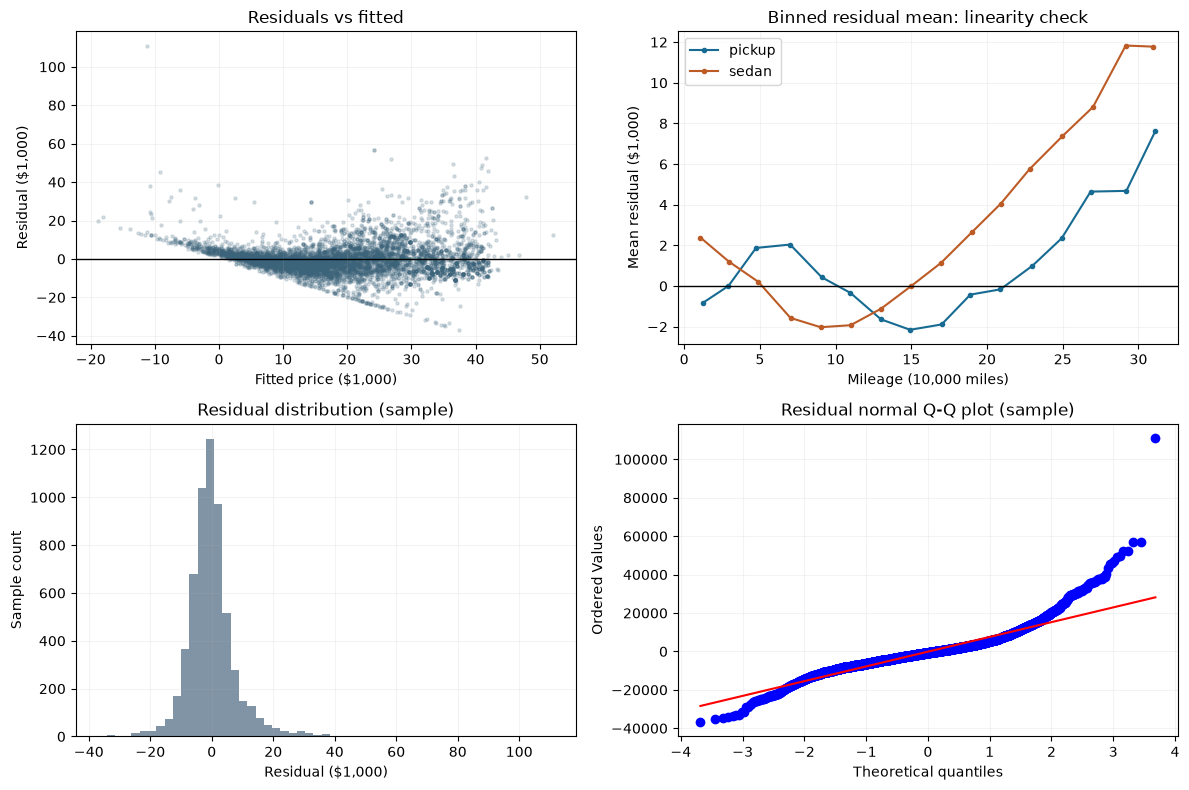

Saved: checkpoint2_outputs\figures\04_residual_diagnostics.png


WindowsPath('checkpoint2_outputs/figures/04_residual_diagnostics.png')

In [34]:
resid=pd.Series(np.asarray(fit_main.resid),index=cp2.index)
fitted=pd.Series(np.asarray(fit_main.fittedvalues),index=cp2.index)
cp2['cp2_residual']=resid
cp2['cp2_fitted']=fitted
cp2['cp2_abs_residual']=resid.abs()

# Residual spread by fitted decile and mileage bin, separately by type.
cp2['cp2_fitted_decile']=pd.qcut(fitted,10,duplicates='drop')
variance_by_decile=cp2.groupby(['type','cp2_fitted_decile'],observed=True).agg(
    n=('id','size'),fitted_mean=('cp2_fitted','mean'),
    residual_mean=('cp2_residual','mean'),residual_sd=('cp2_residual','std'),
    abs_residual_median=('cp2_abs_residual','median')).reset_index()
variance_by_decile['cp2_fitted_decile']=variance_by_decile['cp2_fitted_decile'].astype(str)
save_table(variance_by_decile.round(3),'11_residual_spread_by_fitted_decile.csv',show=20)

cp2['cp2_miles_bin']=pd.cut(cp2['odometer_10k'],np.arange(0,42,2),include_lowest=True)
residual_by_miles=cp2.groupby(['type','cp2_miles_bin'],observed=True).agg(
    n=('id','size'),mileage_mid=('odometer_10k','median'),
    mean_residual=('cp2_residual','mean'),median_residual=('cp2_residual','median'),
    residual_sd=('cp2_residual','std')).reset_index()
residual_by_miles['cp2_miles_bin']=residual_by_miles['cp2_miles_bin'].astype(str)
save_table(residual_by_miles.round(3),'12_residuals_by_mileage_bin.csv',show=20)

fig,axes=plt.subplots(2,2,figsize=(12,8))
rng=np.random.default_rng(CP2_SEED)
chosen=rng.choice(len(cp2),size=min(6000,len(cp2)),replace=False)
axes[0,0].scatter(fitted.iloc[chosen]/1000,resid.iloc[chosen]/1000,s=5,alpha=.18,
                   color='#3b637a',rasterized=True)
axes[0,0].axhline(0,color='black',lw=1)
axes[0,0].set(xlabel='Fitted price ($1,000)',ylabel='Residual ($1,000)',title='Residuals vs fitted')
for kind in ['pickup','sedan']:
    part=residual_by_miles.loc[(residual_by_miles['type']==kind)&(residual_by_miles['n']>=40)]
    axes[0,1].plot(part['mileage_mid'],part['mean_residual']/1000,
                   marker='o',ms=3,color=CP2_COLORS[kind],label=kind)
axes[0,1].axhline(0,color='black',lw=1)
axes[0,1].set(xlabel='Mileage (10,000 miles)',ylabel='Mean residual ($1,000)',
              title='Binned residual mean: linearity check')
axes[0,1].legend()
axes[1,0].hist(resid.iloc[chosen]/1000,bins=55,color='#73889b',alpha=.9)
axes[1,0].set(xlabel='Residual ($1,000)',ylabel='Sample count',title='Residual distribution (sample)')
stats.probplot(resid.iloc[chosen],dist='norm',plot=axes[1,1])
axes[1,1].set_title('Residual normal Q-Q plot (sample)')
for ax in axes.flat: ax.grid(alpha=.15)
fig.tight_layout()
save_figure(fig,'04_residual_diagnostics.png')

### 3.3 Hypothesis tests, confidence intervals, and slope table

The formal null is **H₀: pickup slope − sedan slope = 0**. The research hypothesis is a **positive** interaction when both slopes describe declining prices. Under classical independent, normal, equal-variance errors the usual coefficient statistic follows a Student t distribution. HC3 relaxes equal variance and uses large-sample robust Wald inference; it does **not** correct correlated listings or omitted variables. We report both two-sided and directionally appropriate one-sided p-values.

In [35]:
from scipy.stats import norm, t as student_t

def linear_effect(result, names, weights, label, method='HC3', use_normal=True):
    p=np.asarray(result.params,dtype=float)
    V=np.asarray(result.cov_params(),dtype=float)
    cols=list(names)
    w=np.zeros(len(cols))
    for term,coeff in weights.items():
        w[cols.index(term)]=coeff
    estimate=float(w@p)
    se=float(np.sqrt(max(w@V@w,0)))
    stat=estimate/se if se>0 else np.nan
    if use_normal:
        crit=norm.ppf(.975); p2=float(2*norm.sf(abs(stat)))
        p_positive=float(norm.sf(stat))
    else:
        crit=student_t.ppf(.975,df=result.df_resid)
        p2=float(2*student_t.sf(abs(stat),df=result.df_resid))
        p_positive=float(student_t.sf(stat,df=result.df_resid))
    return {'estimand':label,'inference':method,'estimate_USD_per_10k':estimate,
            'se':se,'test_statistic':stat,'p_two_sided':p2,
            'p_one_sided_positive':p_positive,
            'ci95_low':estimate-crit*se,'ci95_high':estimate+crit*se}

def effect_rows(result, names, method='HC3', use_normal=True):
    return [linear_effect(result,names,{'odometer_10k':1},'Sedan mileage slope',method,use_normal),
            linear_effect(result,names,{'odometer_10k':1,'mileage_x_pickup':1},
                          'Pickup mileage slope',method,use_normal),
            linear_effect(result,names,{'mileage_x_pickup':1},
                          'Pickup minus sedan slope (interaction)',method,use_normal)]

main_effects=pd.DataFrame(effect_rows(robust_main,terms))
classical_effects=pd.DataFrame(effect_rows(fit_main,terms,'Classical t',False))
unadjusted_effects=pd.DataFrame(effect_rows(robust_unadjusted,
                                         list(fit_unadjusted.params.index),'Unadjusted HC3'))
all_effects=pd.concat([main_effects,classical_effects,unadjusted_effects],ignore_index=True)
save_table(all_effects.round(6),'06_mileage_slopes_tests_and_CIs.csv',show=12)

hypothesis=main_effects.loc[main_effects['estimand'].str.startswith('Pickup minus sedan')].iloc[0]
print('Primary estimate (pickup minus sedan): $',round(hypothesis['estimate_USD_per_10k'],2),
      ' per 10,000 miles',sep='')
print('HC3 95% CI: [$',round(hypothesis['ci95_low'],2),', $',round(hypothesis['ci95_high'],2),']',sep='')
print('Two-sided p:',fmt_p(hypothesis['p_two_sided']),
      '| one-sided p for positive interaction:',fmt_p(hypothesis['p_one_sided_positive']))
print('Direction of both slopes:',main_effects.loc[:1,['estimand','estimate_USD_per_10k']].to_string(index=False))
print('Interpretation rule: a positive interaction supports a SMALLER pickup decline only if',
      'the relevant slopes are negative; a CI spanning zero does not establish a difference.')

Saved: checkpoint2_outputs\tables\06_mileage_slopes_tests_and_CIs.csv


,estimand,inference,estimate_USD_per_10k,se,test_statistic,p_two_sided,p_one_sided_positive,ci95_low,ci95_high
0,Sedan mileage slope,HC3,-832.404346,8.027518,-103.693858,0.0,1.0,-848.137993,-816.670700
1,Pickup mileage slope,HC3,-936.866918,9.692421,-96.659747,0.0,1.0,-955.863714,-917.870123
2,Pickup minus sedan slope (interaction),HC3,-104.462572,9.386226,-11.129348,0.0,1.0,-122.859237,-86.065907
3,Sedan mileage slope,Classical t,-832.404346,6.131125,-135.766977,0.0,1.0,-844.421253,-820.387439
4,Pickup mileage slope,Classical t,-936.866918,6.836738,-137.034196,0.0,1.0,-950.266815,-923.467021
5,Pickup minus sedan slope (interaction),Classical t,-104.462572,8.314300,-12.564205,0.0,1.0,-120.758467,-88.166677
6,Sedan mileage slope,Unadjusted HC3,-1250.772699,5.783855,-216.252429,0.0,1.0,-1262.108847,-1239.436552
7,Pickup mileage slope,Unadjusted HC3,-1141.080028,8.334687,-136.907362,0.0,1.0,-1157.415715,-1124.744342
8,Pickup minus sedan slope (interaction),Unadjusted HC3,109.692671,10.144949,10.812541,0.0,0.0,89.808937,129.576406


Primary estimate (pickup minus sedan): $-104.46 per 10,000 miles
HC3 95% CI: [$-122.86, $-86.07]
Two-sided p: < 0.0001 | one-sided p for positive interaction: 1.0000
Direction of both slopes:             estimand  estimate_USD_per_10k
 Sedan mileage slope           -832.404346
Pickup mileage slope           -936.866918
Interpretation rule: a positive interaction supports a SMALLER pickup decline only if the relevant slopes are negative; a CI spanning zero does not establish a difference.


### 3.4 Model fit and adjusted visual comparison

Report in-sample error **separately from inference**. The new scatterplot shows the observed prices; the model lines hold age and the categorical controls at one shared, explicitly identified reference profile. These are conditional adjusted predictions, not two independent raw trend lines.

Saved: checkpoint2_outputs\tables\07_in_sample_model_fit.csv


,model,n,parameters,aic,bic,adj_r2,mae_USD,rmse_USD,r2
0,Unadjusted linear OLS,119016,4,2520130.788,2520169.537,0.517,6790.378,9589.166,0.517
1,Adjusted linear OLS,119016,52,2483018.889,2483522.614,0.646,5554.481,8201.518,0.647


Saved: checkpoint2_outputs\tables\08_adjusted_prediction_grid.csv


,odometer_10k,is_pickup,mileage_x_pickup,vehicle_age,manufacturer_model,condition_model,transmission_model,drive_model,type,prediction,ci_low,ci_high
0,0.000000,1,0.000000,7.0,ford,good,automatic,fwd,pickup,30521.000326,30209.260805,30832.739847
1,0.245631,1,0.245631,7.0,ford,good,automatic,fwd,pickup,30290.876599,29981.929415,30599.823784
2,0.491262,1,0.491262,7.0,ford,good,automatic,fwd,pickup,30060.752873,29754.552376,30366.953370
3,0.736894,1,0.736894,7.0,ford,good,automatic,fwd,pickup,29830.629146,29527.128448,30134.129845
4,0.982525,1,0.982525,7.0,ford,good,automatic,fwd,pickup,29600.505420,29299.656369,29901.354471
5,1.228156,1,1.228156,7.0,ford,good,automatic,fwd,pickup,29370.381694,29072.134855,29668.628532


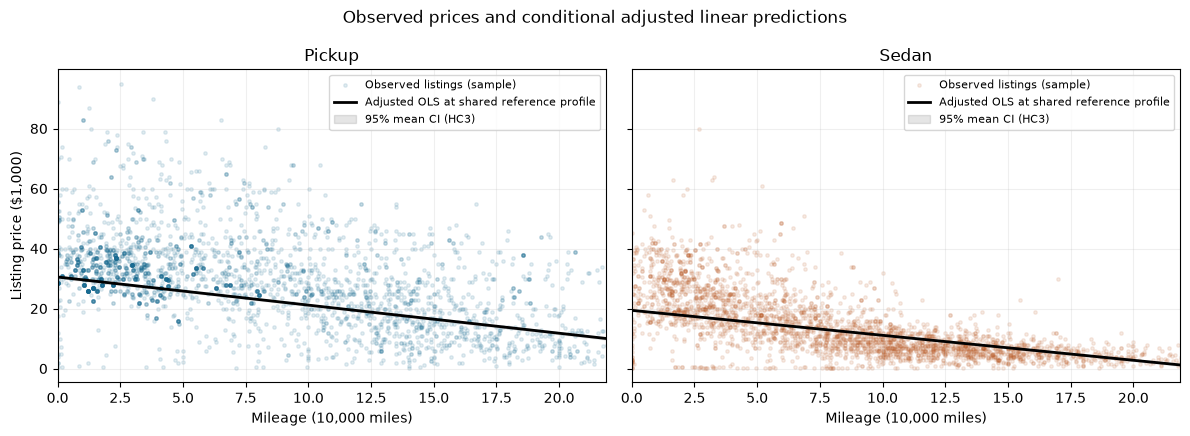

Saved: checkpoint2_outputs\figures\03_adjusted_linear_predictions.png
Reference profile: {'vehicle_age': 7.0, 'manufacturer_model': 'ford', 'condition_model': 'good', 'transmission_model': 'automatic', 'drive_model': 'fwd'}


In [36]:
def scores(y,pred):
    return {'mae_USD':mean_absolute_error(y,pred),
            'rmse_USD':np.sqrt(mean_squared_error(y,pred)),
            'r2':r2_score(y,pred)}
model_fit_rows=[]
for name,fit in [('Unadjusted linear OLS',fit_unadjusted),('Adjusted linear OLS',fit_main)]:
    model_fit_rows.append({'model':name,'n':int(fit.nobs),'parameters':int(fit.df_model+1),
                           'aic':fit.aic,'bic':fit.bic,'adj_r2':fit.rsquared_adj,
                           **scores(cp2['price'],fit.fittedvalues)})
model_fit_table=pd.DataFrame(model_fit_rows)
save_table(model_fit_table.round(3),'07_in_sample_model_fit.csv')

# Choose a single shared reference profile from observed covariates.
shared=set(cp2.loc[cp2['is_pickup'].eq(1),'manufacturer_model']) & \
       set(cp2.loc[cp2['is_pickup'].eq(0),'manufacturer_model'])
if not shared:
    raise ValueError('No manufacturer appears in both groups: reference predictions need revision.')
manufacturer_ref=cp2.loc[cp2['manufacturer_model'].isin(shared),'manufacturer_model'].mode().iloc[0]
profile={'vehicle_age':float(cp2['vehicle_age'].median()),
         'manufacturer_model':manufacturer_ref}
for cat in CATS_MODEL[1:]:
    profile[cat]=cp2[cat].mode().iloc[0]

max_mileage=float(min(25,cp2['odometer_10k'].quantile(.975)))
miles_grid=np.linspace(0,max_mileage,90)
frames=[]
for kind,flag in [('pickup',1),('sedan',0)]:
    new=pd.DataFrame({'odometer_10k':miles_grid,'is_pickup':flag,
                      'mileage_x_pickup':miles_grid*flag,**profile})
    pred=robust_main.get_prediction(new).summary_frame(alpha=.05)
    new['type']=kind
    new['prediction']=pred['mean'].to_numpy()
    new['ci_low']=pred['mean_ci_lower'].to_numpy()
    new['ci_high']=pred['mean_ci_upper'].to_numpy()
    frames.append(new)
curves=pd.concat(frames,ignore_index=True)
save_table(curves,'08_adjusted_prediction_grid.csv',show=6)
fig,axes=plt.subplots(1,2,figsize=(12,4.4),sharex=True,sharey=True)
for ax,kind in zip(axes,['pickup','sedan']):
    sub=cp2.loc[cp2['type'].eq(kind)].sample(n=min(3000,(cp2['type']==kind).sum()),
                                            random_state=CP2_SEED)
    ax.scatter(sub['odometer_10k'],sub['price']/1000,s=6,alpha=.12,
               color=CP2_COLORS[kind],rasterized=True,label='Observed listings (sample)')
    pred=curves.loc[curves['type'].eq(kind)]
    ax.plot(pred['odometer_10k'],pred['prediction']/1000,color='black',lw=2,
            label='Adjusted OLS at shared reference profile')
    ax.fill_between(pred['odometer_10k'].to_numpy(),pred['ci_low'].to_numpy()/1000,
                    pred['ci_high'].to_numpy()/1000,color='black',alpha=.10,label='95% mean CI (HC3)')
    ax.set(title=kind.title(),xlabel='Mileage (10,000 miles)',xlim=(0,max_mileage))
    ax.grid(alpha=.2)
    ax.legend(fontsize=8,loc='upper right')
axes[0].set_ylabel('Listing price ($1,000)')
fig.suptitle('Observed prices and conditional adjusted linear predictions')
fig.tight_layout()
save_figure(fig,'03_adjusted_linear_predictions.png')
print('Reference profile:',profile)

### 3.5 Influence and repeated listings

Very unusual listings can shift the fitted slopes even after numeric cleaning. Inspect leverage and Cook's distance; threshold counts are **review flags**, not automatic grounds for deletion. Repeated known VINs can cause correlated errors, so compare HC3 with VIN-clustered standard errors. Unknown VINs still prevent a complete independence check.

In [37]:
# OLS influence is diagnostic; it is not a decision rule that any flagged record is false.
influence=fit_main.get_influence()
hat=np.asarray(influence.hat_matrix_diag)
cook=np.asarray(influence.cooks_distance[0])
threshold_leverage=2*p/len(cp2)
threshold_cook=4/len(cp2)
influence_summary=pd.DataFrame([
    {'metric':'Model parameters','value':p},
    {'metric':'Leverage threshold 2p/n','value':threshold_leverage},
    {'metric':'Listings above leverage threshold','value':int(np.sum(hat>threshold_leverage))},
    {'metric':'Cook distance threshold 4/n','value':threshold_cook},
    {'metric':'Listings above Cook threshold','value':int(np.sum(cook>threshold_cook))},
    {'metric':'Maximum leverage','value':float(np.nanmax(hat))},
    {'metric':'Maximum Cook distance','value':float(np.nanmax(cook))}
])
save_table(influence_summary,'13_influence_summary.csv')

cp2['cp2_cooks_distance']=cook
most_influential=cp2.nlargest(15,'cp2_cooks_distance')[
    ['id','type','price','odometer','year','vehicle_age','cp2_fitted',
     'cp2_residual','cp2_cooks_distance','known_vin_repeated']].copy()
save_table(most_influential.round(3),'14_most_influential_listings.csv',show=15)

covariance_comparison=main_effects.copy()
covariance_comparison['source']='HC3 robust (primary)'
if cp2['known_vin_repeated'].any():
    clustered=fit_main.get_robustcov_results(cov_type='cluster',
                                            groups=cp2['vehicle_cluster'].to_numpy())
    cluster_effects=pd.DataFrame(effect_rows(clustered,terms,'Known-VIN clustered (normal approximation)'))
    cluster_effects['source']='Known-VIN clustered (sensitivity)'
    covariance_comparison=pd.concat([covariance_comparison,cluster_effects],ignore_index=True)
    print('VIN clustering performed; unknown VIN records remain unique listing clusters.')
else:
    print('No repeated valid VINs available; VIN clustering comparison omitted.')
save_table(covariance_comparison.round(6),'15_covariance_sensitivity.csv',show=8)

Saved: checkpoint2_outputs\tables\13_influence_summary.csv


,metric,value
0,Model parameters,52.000000
1,Leverage threshold 2p/n,0.000874
2,Listings above leverage threshold,7133.000000
3,Cook distance threshold 4/n,0.000034
4,Listings above Cook threshold,5309.000000
5,Maximum leverage,0.026147
6,Maximum Cook distance,0.016580


Saved: checkpoint2_outputs\tables\14_most_influential_listings.csv


,id,type,price,odometer,year,vehicle_age,cp2_fitted,cp2_residual,cp2_cooks_distance,known_vin_repeated
52104,7309794306,sedan,74991,29921.0,2014.0,7.0,24633.102,50357.898,0.017,True
87016,7309794276,sedan,74991,29921.0,2014.0,7.0,24633.102,50357.898,0.017,True
25992,7304661436,sedan,52000,29970.0,2010.0,11.0,19909.581,32090.419,0.007,False
91151,7316371253,sedan,68500,40.0,1955.0,66.0,6813.388,61686.612,0.006,False
15892,7315520204,sedan,99888,46113.0,1940.0,81.0,-11196.475,111084.475,0.004,False
17793,7316789567,sedan,99888,46113.0,1940.0,81.0,-11196.475,111084.475,0.004,False
78127,7316015449,sedan,75995,49118.0,2018.0,3.0,43480.913,32514.087,0.004,False
18134,7316446771,sedan,79991,8914.0,2018.0,3.0,46531.972,33459.028,0.004,False
53854,7307007710,sedan,79900,27503.0,2018.0,3.0,47864.939,32035.061,0.004,True
57024,7307007538,sedan,79900,27503.0,2018.0,3.0,47864.939,32035.061,0.004,True


VIN clustering performed; unknown VIN records remain unique listing clusters.
Saved: checkpoint2_outputs\tables\15_covariance_sensitivity.csv


,estimand,inference,estimate_USD_per_10k,se,test_statistic,p_two_sided,p_one_sided_positive,ci95_low,ci95_high,source
0,Sedan mileage slope,HC3,-832.404346,8.027518,-103.693858,0.000000,1.000000,-848.137993,-816.670700,HC3 robust (primary)
1,Pickup mileage slope,HC3,-936.866918,9.692421,-96.659747,0.000000,1.000000,-955.863714,-917.870123,HC3 robust (primary)
2,Pickup minus sedan slope (interaction),HC3,-104.462572,9.386226,-11.129348,0.000000,1.000000,-122.859237,-86.065907,HC3 robust (primary)
3,Sedan mileage slope,Known-VIN clustered (normal approximation),-832.404346,12.119176,-68.684895,0.000000,1.000000,-856.157495,-808.651197,Known-VIN clustered (sensitivity)
4,Pickup mileage slope,Known-VIN clustered (normal approximation),-936.866918,24.230114,-38.665394,0.000000,1.000000,-984.357069,-889.376767,Known-VIN clustered (sensitivity)
5,Pickup minus sedan slope (interaction),Known-VIN clustered (normal approximation),-104.462572,27.234600,-3.835657,0.000125,0.999937,-157.841408,-51.083736,Known-VIN clustered (sensitivity)


,estimand,inference,estimate_USD_per_10k,se,test_statistic,p_two_sided,p_one_sided_positive,ci95_low,ci95_high,source
0,Sedan mileage slope,HC3,-832.404346,8.027518,-103.693858,0.000000,1.000000,-848.137993,-816.670700,HC3 robust (primary)
1,Pickup mileage slope,HC3,-936.866918,9.692421,-96.659747,0.000000,1.000000,-955.863714,-917.870123,HC3 robust (primary)
2,Pickup minus sedan slope (interaction),HC3,-104.462572,9.386226,-11.129348,0.000000,1.000000,-122.859237,-86.065907,HC3 robust (primary)
3,Sedan mileage slope,Known-VIN clustered (normal approximation),-832.404346,12.119176,-68.684895,0.000000,1.000000,-856.157495,-808.651197,Known-VIN clustered (sensitivity)
4,Pickup mileage slope,Known-VIN clustered (normal approximation),-936.866918,24.230114,-38.665394,0.000000,1.000000,-984.357069,-889.376767,Known-VIN clustered (sensitivity)
5,Pickup minus sedan slope (interaction),Known-VIN clustered (normal approximation),-104.462572,27.234600,-3.835657,0.000125,0.999937,-157.841408,-51.083736,Known-VIN clustered (sensitivity)


### 3.6 Challenge the constant-slope model

Checkpoint 1's binned curves appeared to flatten at higher mileage. Add mileage squared, its interaction with vehicle type, and age squared. A **joint robust Wald test** asks whether the added curvature terms improve functional form; local mileage derivatives at specified mileages replace a single slope in this model. A small p-value diagnoses the linear specification; it does not establish causation.

Saved: checkpoint2_outputs\tables\16_quadratic_model_joint_test.csv


,test,statistic_chi2,degrees_freedom,p_value,linear_adjusted_AIC,quadratic_adjusted_AIC,linear_adjusted_R2,quadratic_adjusted_R2
0,HC3 joint Wald: extra quadratic terms = 0,7069.714953,3,0.0,2.483019e+06,2.463933e+06,0.646478,0.698865


Saved: checkpoint2_outputs\tables\17_quadratic_local_mileage_effects.csv


,estimand,inference,estimate_USD_per_10k,se,test_statistic,p_two_sided,p_one_sided_positive,ci95_low,ci95_high,mileage_miles
0,Sedan,Quadratic HC3 local derivative,-864.01104,12.89568,-67.00005,0.0,1.0,-889.28611,-838.73598,50000
1,Pickup,Quadratic HC3 local derivative,-695.21639,17.01074,-40.86927,0.0,1.0,-728.55681,-661.87596,50000
2,Pickup minus sedan,Quadratic HC3 local derivative,168.79466,16.82283,10.03367,0.0,0.0,135.82252,201.76679,50000
3,Sedan,Quadratic HC3 local derivative,-501.48106,7.48576,-66.99133,0.0,1.0,-516.15288,-486.80923,100000
4,Pickup,Quadratic HC3 local derivative,-657.98304,10.48070,-62.78043,0.0,1.0,-678.52484,-637.44124,100000
5,Pickup minus sedan,Quadratic HC3 local derivative,-156.50199,9.43843,-16.58136,0.0,1.0,-175.00096,-138.00301,100000
6,Sedan,Quadratic HC3 local derivative,-138.95107,8.14490,-17.05988,0.0,1.0,-154.91479,-122.98735,150000
7,Pickup,Quadratic HC3 local derivative,-620.74970,8.52664,-72.80117,0.0,1.0,-637.46161,-604.03778,150000
8,Pickup minus sedan,Quadratic HC3 local derivative,-481.79863,10.63190,-45.31634,0.0,1.0,-502.63677,-460.96049,150000
9,Sedan,Quadratic HC3 local derivative,223.57892,14.04304,15.92098,0.0,0.0,196.05506,251.10277,200000


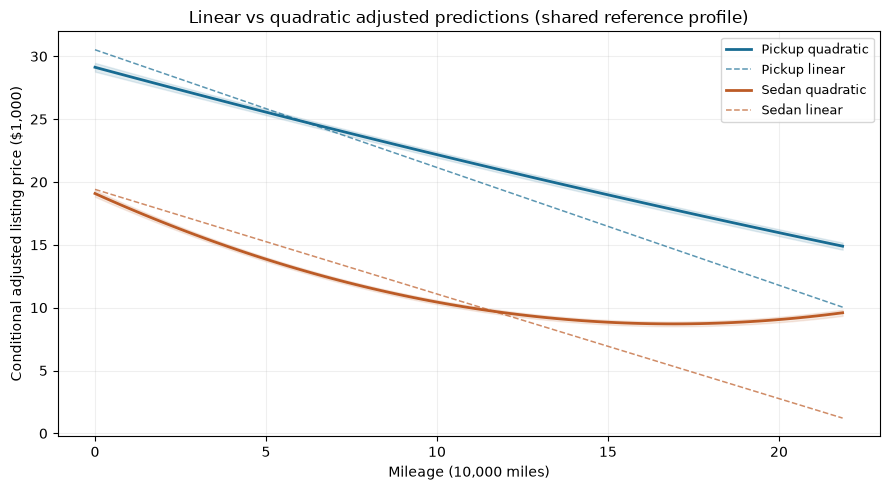

Saved: checkpoint2_outputs\figures\05_linear_vs_quadratic.png


WindowsPath('checkpoint2_outputs/figures/05_linear_vs_quadratic.png')

In [38]:
fit_quad=ols(FORMULA_QUAD,data=cp2).fit()
robust_quad=fit_quad.get_robustcov_results(cov_type='HC3')
qterms=list(fit_quad.params.index)
added=['I(odometer_10k ** 2)','I(odometer_10k ** 2):is_pickup','I(vehicle_age ** 2)']
assert all(x in qterms for x in added),qterms
R=np.zeros((len(added),len(qterms)))
for i,term in enumerate(added): R[i,qterms.index(term)]=1
joint=robust_quad.wald_test(R,use_f=False,scalar=True)
wald_table=pd.DataFrame([{'test':'HC3 joint Wald: extra quadratic terms = 0',
                           'statistic_chi2':float(joint.statistic),
                           'degrees_freedom':len(added),'p_value':float(joint.pvalue),
                           'linear_adjusted_AIC':fit_main.aic,
                           'quadratic_adjusted_AIC':fit_quad.aic,
                           'linear_adjusted_R2':fit_main.rsquared_adj,
                           'quadratic_adjusted_R2':fit_quad.rsquared_adj}])
save_table(wald_table.round(6),'16_quadratic_model_joint_test.csv')

local_rows=[]
for miles in [5,10,15,20]:
    for label,weights in [
        ('Sedan',{'odometer_10k':1,'I(odometer_10k ** 2)':2*miles}),
        ('Pickup',{'odometer_10k':1,'mileage_x_pickup':1,
                   'I(odometer_10k ** 2)':2*miles,
                   'I(odometer_10k ** 2):is_pickup':2*miles}),
        ('Pickup minus sedan',{'mileage_x_pickup':1,
                               'I(odometer_10k ** 2):is_pickup':2*miles})]:
        row=linear_effect(robust_quad,qterms,weights,label,method='Quadratic HC3 local derivative')
        row['mileage_miles']=int(miles*10000)
        local_rows.append(row)
local_table=pd.DataFrame(local_rows)
save_table(local_table.round(5),'17_quadratic_local_mileage_effects.csv',show=15)

fig,ax=plt.subplots(figsize=(9,5))
for kind,flag in [('pickup',1),('sedan',0)]:
    grid=pd.DataFrame({'odometer_10k':miles_grid,'is_pickup':flag,
                       'mileage_x_pickup':flag*miles_grid,**profile})
    pred=robust_quad.get_prediction(grid).summary_frame(alpha=.05)
    ax.plot(miles_grid,pred['mean']/1000,color=CP2_COLORS[kind],lw=2,
            label=f'{kind.title()} quadratic')
    ax.fill_between(miles_grid,pred['mean_ci_lower'].to_numpy()/1000,
                    pred['mean_ci_upper'].to_numpy()/1000,color=CP2_COLORS[kind],alpha=.12)
    linear_pred=robust_main.predict(grid)
    ax.plot(miles_grid,linear_pred/1000,ls='--',lw=1.1,color=CP2_COLORS[kind],alpha=.7,
            label=f'{kind.title()} linear')
ax.set(xlabel='Mileage (10,000 miles)',ylabel='Conditional adjusted listing price ($1,000)',
       title='Linear vs quadratic adjusted predictions (shared reference profile)')
ax.grid(alpha=.2);ax.legend(fontsize=9)
fig.tight_layout()
save_figure(fig,'05_linear_vs_quadratic.png')

### 3.7 Repeated train/test splits across random seeds

The full-data OLS estimate is deterministic: changing a random seed does not change it. To assess **sampling stability and out-of-sample performance**, use five 80/20 **vehicle-cluster-disjoint** splits. Fit unadjusted linear, adjusted linear, adjusted quadratic, and adjusted log-price specifications. Compare original-dollar MAE/RMSE/R² and the estimated mileage difference. A split-to-split range is a **stability diagnostic, not a 95% confidence interval**.

Saved: checkpoint2_outputs\tables\18_repeated_split_all_runs.csv


,seed,model,train_n,test_n,mae_USD,rmse_USD,r2,mileage_slope_difference_at_100k,slope_units
0,11,Unadjusted linear,95409,23607,6802.05145,9612.66063,0.52016,134.17564,USD per 10k
1,11,Adjusted linear,95409,23607,5658.33404,8270.10901,0.64484,-94.41157,USD per 10k
2,11,Adjusted quadratic,95409,23607,5198.61349,7710.27372,0.69129,-150.21994,USD per 10k
3,11,Adjusted log-price,95409,23607,5427.00449,8125.76361,0.65713,0.03144,log(price) per 10k
4,21,Unadjusted linear,94862,24154,6708.36822,9442.67577,0.50990,85.97407,USD per 10k
5,21,Adjusted linear,94862,24154,5628.07148,8138.17516,0.63596,-132.65719,USD per 10k
6,21,Adjusted quadratic,94862,24154,5066.77819,7455.05839,0.69451,-181.88625,USD per 10k
7,21,Adjusted log-price,94862,24154,5565.46354,8300.61617,0.62128,0.02957,log(price) per 10k
8,31,Unadjusted linear,94918,24098,6904.69612,9720.00525,0.51118,120.68104,USD per 10k
9,31,Adjusted linear,94918,24098,5521.27874,8248.63753,0.64797,-92.21127,USD per 10k


Saved: checkpoint2_outputs\tables\19_repeated_split_model_comparison.csv


,model,repeats,mean_test_MAE,sd_test_MAE,mean_test_RMSE,sd_test_RMSE,mean_test_R2,sd_test_R2,mean_slope_diff_at_100k,min_slope_diff_at_100k,max_slope_diff_at_100k
0,Adjusted linear,5,5556.8231,80.9862,8186.7561,66.7704,0.6451,0.0053,-101.1822,-132.6572,-88.0218
1,Adjusted log-price,5,5421.1232,167.5429,8188.9139,205.8056,0.6446,0.0205,0.0311,0.0296,0.0319
2,Adjusted quadratic,5,5054.0260,98.9129,7554.1457,116.5956,0.6978,0.0059,-154.7483,-181.8862,-141.4768
3,Unadjusted linear,5,6756.5546,113.7560,9535.4152,137.8242,0.5186,0.0091,118.1597,85.9741,134.1756


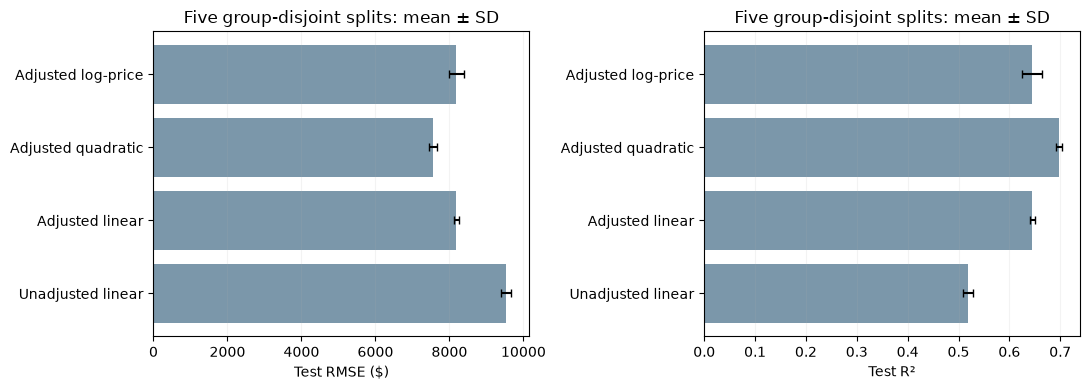

Saved: checkpoint2_outputs\figures\06_model_comparison_across_seeds.png


WindowsPath('checkpoint2_outputs/figures/06_model_comparison_across_seeds.png')

In [39]:
cp2['odometer_sq']=cp2['odometer_10k']**2
cp2['odometer_sq_x_pickup']=cp2['odometer_sq']*cp2['is_pickup']
cp2['age_sq']=cp2['vehicle_age']**2

specs={
 'Unadjusted linear': {'numeric':['odometer_10k','is_pickup','mileage_x_pickup'],
                       'categorical':[],'log_target':False},
 'Adjusted linear': {'numeric':['odometer_10k','is_pickup','mileage_x_pickup','vehicle_age'],
                     'categorical':CATS_MODEL,'log_target':False},
 'Adjusted quadratic': {'numeric':['odometer_10k','is_pickup','mileage_x_pickup','vehicle_age',
                                    'odometer_sq','odometer_sq_x_pickup','age_sq'],
                        'categorical':CATS_MODEL,'log_target':False},
 'Adjusted log-price': {'numeric':['odometer_10k','is_pickup','mileage_x_pickup','vehicle_age'],
                         'categorical':CATS_MODEL,'log_target':True}
}

def onehot():
    try:
        return OneHotEncoder(handle_unknown='ignore',sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore',sparse=True)

seeds=[11,21,31,41,51]
splitter=GroupShuffleSplit(n_splits=len(seeds),test_size=.2,random_state=CP2_SEED)
# To ensure five explicit, reproducible seeds, build each split separately.
run_rows=[]
for seed in seeds:
    tr,te=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=seed).split(
        cp2,groups=cp2['vehicle_cluster']))
    assert not(set(cp2.iloc[tr]['vehicle_cluster']) & set(cp2.iloc[te]['vehicle_cluster']))
    ytr=cp2['price'].iloc[tr].to_numpy(dtype=float)
    yte=cp2['price'].iloc[te].to_numpy(dtype=float)
    for model_name,spec in specs.items():
        transformers=[('num','passthrough',spec['numeric'])]
        if spec['categorical']:
            transformers.append(('cat',onehot(),spec['categorical']))
        pre=ColumnTransformer(transformers,sparse_threshold=.75)
        model=Pipeline([('pre',pre),('reg',LinearRegression())])
        Xtr=cp2.iloc[tr][spec['numeric']+spec['categorical']]
        Xte=cp2.iloc[te][spec['numeric']+spec['categorical']]
        model.fit(Xtr,np.log(ytr) if spec['log_target'] else ytr)
        pred_test=model.predict(Xte)
        if spec['log_target']:
            # Duan's global smearing factor: approximate retransformation for mean price.
            log_resid=np.log(ytr)-model.predict(Xtr)
            smear=float(np.mean(np.exp(log_resid)))
            pred_test=np.exp(np.clip(pred_test,-20,20))*smear
        numerics=spec['numeric']
        beta=model.named_steps['reg'].coef_[:len(numerics)]
        slope_diff=float(beta[numerics.index('mileage_x_pickup')])
        if 'odometer_sq_x_pickup' in numerics:
            slope_diff+=20*float(beta[numerics.index('odometer_sq_x_pickup')])
        run_rows.append({'seed':seed,'model':model_name,
                         'train_n':len(tr),'test_n':len(te),
                         **scores(yte,pred_test),
                         'mileage_slope_difference_at_100k':slope_diff,
                         'slope_units':'log(price) per 10k' if spec['log_target'] else 'USD per 10k'})

seed_runs=pd.DataFrame(run_rows)
save_table(seed_runs.round(5),'18_repeated_split_all_runs.csv',show=20)
seed_summary=seed_runs.groupby('model',as_index=False).agg(
    repeats=('seed','size'),mean_test_MAE=('mae_USD','mean'),sd_test_MAE=('mae_USD','std'),
    mean_test_RMSE=('rmse_USD','mean'),sd_test_RMSE=('rmse_USD','std'),
    mean_test_R2=('r2','mean'),sd_test_R2=('r2','std'),
    mean_slope_diff_at_100k=('mileage_slope_difference_at_100k','mean'),
    min_slope_diff_at_100k=('mileage_slope_difference_at_100k','min'),
    max_slope_diff_at_100k=('mileage_slope_difference_at_100k','max'))
save_table(seed_summary.round(4),'19_repeated_split_model_comparison.csv')

fig,axes=plt.subplots(1,2,figsize=(11,4))
models=list(specs)
for i,metric in enumerate(['rmse_USD','r2']):
    means=[seed_runs.loc[seed_runs['model'].eq(m),metric].mean() for m in models]
    sds=[seed_runs.loc[seed_runs['model'].eq(m),metric].std() for m in models]
    axes[i].barh(models,means,xerr=sds,color='#64859b',capsize=3,alpha=.85)
    axes[i].set(xlabel='Test RMSE ($)' if i==0 else 'Test R²',
                title='Five group-disjoint splits: mean ± SD')
    axes[i].grid(alpha=.15,axis='x')
fig.tight_layout()
save_figure(fig,'06_model_comparison_across_seeds.png')

### 3.8 Sensitivity to the data-quality decisions in Checkpoint 1

Change **one rule at a time** while preserving the original adjusted model and using HC3 uncertainty. Compare sign, magnitude, intervals, and retained group sizes. The original sample remains the primary analysis; alternative restrictions examine robustness rather than selecting whichever result is most significant.

Relaxed cleaning admits 57 additional listings.
Saved: checkpoint2_outputs\tables\20_cleaning_and_influence_sensitivity.csv


,scenario,n,n_pickup,n_sedan,sedan_slope,pickup_slope,interaction,interaction_95ci_low,interaction_95ci_high,interaction_p_two_sided
0,Primary CP1 sample,119016,40481,78535,-832.40435,-936.86692,-104.46257,-122.85924,-86.06591,0.0
1,"Exclude price below $1,000",116725,40250,76475,-891.05513,-962.31252,-71.25739,-89.47082,-53.04395,0.0
2,"Exclude mileage below 1,000",117706,39992,77714,-860.87435,-956.02253,-95.14818,-113.42362,-76.87273,0.0
3,Exclude condition marked new,118801,40419,78382,-830.89961,-932.86968,-101.97007,-120.35501,-83.58512,0.0
4,Exclude age over 30 years,117141,39577,77564,-446.38726,-611.28115,-164.89389,-181.63383,-148.15395,0.0
5,"Restrict mileage to 250,000",117854,39766,78088,-885.32031,-1006.38405,-121.06374,-140.52599,-101.60149,0.0
6,Conservative used listings,113459,38796,74663,-534.61396,-651.53250,-116.91854,-133.24291,-100.59417,0.0
7,Exclude top 1% Cook distance,117825,40114,77711,-699.93187,-832.84239,-132.91051,-149.63090,-116.19012,0.0
8,Keep one listing per known VIN,68342,17899,50443,-668.85743,-1154.99978,-486.14235,-515.27303,-457.01167,0.0
9,Relax original price/mileage upper bounds,119073,40502,78571,-840.01777,-941.14058,-101.12281,-119.95211,-82.29350,0.0


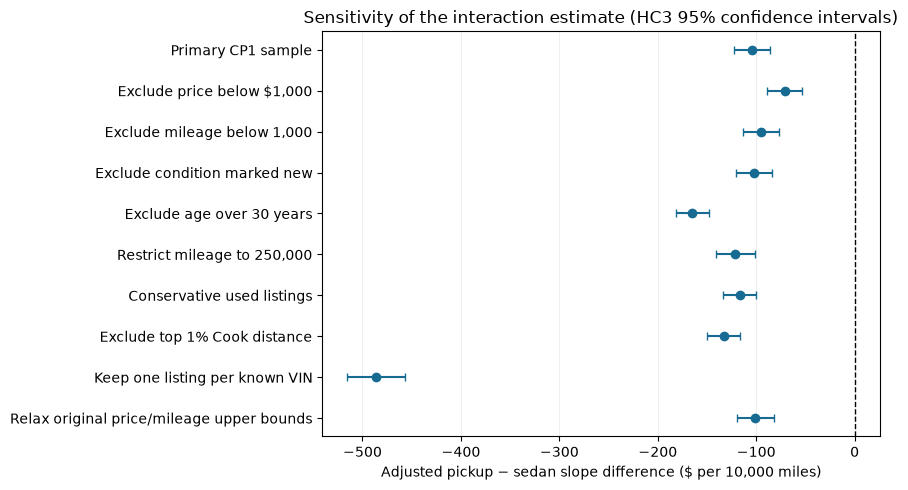

Saved: checkpoint2_outputs\figures\07_interaction_sensitivity.png


WindowsPath('checkpoint2_outputs/figures/07_interaction_sensitivity.png')

In [40]:
first_known_vin=~cp2['vin_key'].duplicated(keep='first') | cp2['vin_key'].isna()
scenarios={
  'Primary CP1 sample':np.ones(len(cp2),dtype=bool),
  'Exclude price below $1,000':cp2['price'].ge(1000).to_numpy(),
  'Exclude mileage below 1,000':cp2['odometer'].ge(1000).to_numpy(),
  'Exclude condition marked new':~cp2['condition'].astype(str).str.lower().eq('new').to_numpy(),
  'Exclude age over 30 years':cp2['vehicle_age'].le(30).to_numpy(),
  'Restrict mileage to 250,000':cp2['odometer'].le(250000).to_numpy(),
  'Conservative used listings':(cp2['price'].ge(1000) & cp2['odometer'].ge(1000) &
      cp2['vehicle_age'].between(1,30) & ~cp2['condition'].astype(str).str.lower().eq('new')).to_numpy(),
  'Exclude top 1% Cook distance':(cp2['cp2_cooks_distance'].le(np.nanquantile(cook,.99))).to_numpy(),
}
if cp2['known_vin_repeated'].any():
    scenarios['Keep one listing per known VIN']=first_known_vin.to_numpy()

sensitivity=[]
for name,mask in scenarios.items():
    sub=cp2.loc[mask]
    if name=='Primary CP1 sample':
        r=robust_main
        names=terms
    else:
        f=ols(FORMULA_MAIN,data=sub).fit()
        r=f.get_robustcov_results(cov_type='HC3')
        names=list(f.params.index)
    eff=pd.DataFrame(effect_rows(r,names)).set_index('estimand')
    si=eff.loc['Sedan mileage slope']
    pi=eff.loc['Pickup mileage slope']
    di=eff.loc['Pickup minus sedan slope (interaction)']
    sensitivity.append({'scenario':name,'n':len(sub),
                        'n_pickup':int(sub['is_pickup'].sum()),
                        'n_sedan':int((1-sub['is_pickup']).sum()),
                        'sedan_slope':si['estimate_USD_per_10k'],
                        'pickup_slope':pi['estimate_USD_per_10k'],
                        'interaction':di['estimate_USD_per_10k'],
                        'interaction_95ci_low':di['ci95_low'],
                        'interaction_95ci_high':di['ci95_high'],
                        'interaction_p_two_sided':di['p_two_sided']})
# Optional counterfactual cleaning check: re-admit reasonably plausible records from the
# ORIGINAL precleaning type subset, rather than only tightening the retained sample.
if 'subset_type' in globals() and {'price','odometer','year','type'}.issubset(subset_type.columns):
    source_alt=subset_type.loc[
        subset_type['price'].between(101,150000) &
        subset_type['odometer'].between(1,450000) &
        subset_type['year'].between(1900,2021)
    ].copy()
    if len(source_alt)>len(cp2):
        source_alt['vehicle_age']=2021-source_alt['year']
        source_alt['odometer_10k']=source_alt['odometer']/10000
        source_alt['is_pickup']=source_alt['type'].eq('pickup').astype(int)
        source_alt['mileage_x_pickup']=source_alt['odometer_10k']*source_alt['is_pickup']
        for raw_col,model_col in zip(CATS,CATS_MODEL):
            values=source_alt[raw_col].fillna('unknown').astype(str)
            original_kept=set(cp2[model_col].unique())-{'other_rare'}
            source_alt[model_col]=values.where(values.isin(original_kept),'other_rare')
        relaxed_fit=ols(FORMULA_MAIN,data=source_alt).fit()
        relaxed_robust=relaxed_fit.get_robustcov_results(cov_type='HC3')
        relaxed_eff=pd.DataFrame(effect_rows(relaxed_robust,list(relaxed_fit.params.index))).set_index('estimand')
        si=relaxed_eff.loc['Sedan mileage slope']
        pi=relaxed_eff.loc['Pickup mileage slope']
        di=relaxed_eff.loc['Pickup minus sedan slope (interaction)']
        sensitivity.append({'scenario':'Relax original price/mileage upper bounds',
                            'n':len(source_alt),'n_pickup':int(source_alt['is_pickup'].sum()),
                            'n_sedan':int((1-source_alt['is_pickup']).sum()),
                            'sedan_slope':si['estimate_USD_per_10k'],
                            'pickup_slope':pi['estimate_USD_per_10k'],
                            'interaction':di['estimate_USD_per_10k'],
                            'interaction_95ci_low':di['ci95_low'],
                            'interaction_95ci_high':di['ci95_high'],
                            'interaction_p_two_sided':di['p_two_sided']})
        print('Relaxed cleaning admits',len(source_alt)-len(cp2),'additional listings.')
    else:
        print('Relaxed cleaning admits no additional listings; scenario omitted.')
else:
    print('Precleaning subset_type unavailable; relaxation scenario omitted.')

sensitivity_table=pd.DataFrame(sensitivity)
save_table(sensitivity_table.round(5),'20_cleaning_and_influence_sensitivity.csv',show=14)

fig,ax=plt.subplots(figsize=(9,5))
y=np.arange(len(sensitivity_table))
v=sensitivity_table['interaction'].to_numpy()
lo=v-sensitivity_table['interaction_95ci_low'].to_numpy()
hi=sensitivity_table['interaction_95ci_high'].to_numpy()-v
ax.errorbar(v,y,xerr=[lo,hi],fmt='o',capsize=3,color='#176b92')
ax.axvline(0,color='black',ls='--',lw=1)
ax.set_yticks(y,sensitivity_table['scenario'])
ax.invert_yaxis()
ax.set(xlabel='Adjusted pickup − sedan slope difference ($ per 10,000 miles)',
       title='Sensitivity of the interaction estimate (HC3 95% confidence intervals)')
ax.grid(axis='x',alpha=.2)
fig.tight_layout()
save_figure(fig,'07_interaction_sensitivity.png')

## 4. Evaluation of hypothesis and assumptions

The following ledger separates **testable diagnostics** from **unverifiable assumptions**. A small p-value alone does not establish practical importance or a causal mileage effect. Large-sample HC3 inference is a reasonable descriptive approach only to the extent that the conditional model is useful and residual dependence is limited.

In [41]:
ledger=pd.DataFrame([
 {'assumption_or_issue':'Correct sample and unique listing IDs','diagnostic':'Checkpoint 1 rules, ID and source audit',
  'status':'Verified mechanically for available input','remaining_limitation':'Craigslist selection is not random'},
 {'assumption_or_issue':'Outcome and predictor distributions','diagnostic':'Group quantiles, skew, ECDF, tail counts',
  'status':'Described, not required to be normal','remaining_limitation':'Rare and unusual listings may shift coefficients'},
 {'assumption_or_issue':'Functional form','diagnostic':'Binned residuals, quadratic extension, joint robust Wald test',
  'status':'Empirically assessed','remaining_limitation':'Other nonlinearities and interactions remain possible'},
 {'assumption_or_issue':'Homoskedasticity','diagnostic':'Breusch-Pagan and residual spread by fitted decile',
  'status':'Empirically assessed; HC3 used for primary inference',
  'remaining_limitation':'HC3 does not correct dependence or model misspecification'},
 {'assumption_or_issue':'Normal errors for classical finite-sample t','diagnostic':'Residual Q-Q and Jarque-Bera',
  'status':'Described; not required for asymptotic HC3 Wald inference',
  'remaining_limitation':'Large n makes JB sensitive to small deviations'},
 {'assumption_or_issue':'Full-rank and stable numerical design','diagnostic':'Rank, condition number, VIF, rare-level regrouping',
  'status':'Empirically assessed','remaining_limitation':'Unobserved confounding unaffected'},
 {'assumption_or_issue':'No dominating observations','diagnostic':'Leverage, Cook distance, exclusion sensitivity',
  'status':'Empirically assessed','remaining_limitation':'No data-driven removal treated as proof of error'},
 {'assumption_or_issue':'Independent listing errors','diagnostic':'Known-VIN repeats, cluster-robust comparison, group-disjoint splits',
  'status':'Only partially assessed','remaining_limitation':'Missing VINs and geography/seller dependence remain'},
 {'assumption_or_issue':'Exogeneity / no omitted confounders','diagnostic':'Not testable using these records',
  'status':'Unverified','remaining_limitation':'Listings, brands, trims, seller decisions and market factors may confound'},
 {'assumption_or_issue':'Selection and external validity','diagnostic':'Exclusion differences and alternative filtering',
  'status':'Partially assessed','remaining_limitation':'Asking prices in April–May 2021 are not realized transactions'},
 {'assumption_or_issue':'Stable conclusion under split sampling','diagnostic':'Five vehicle-group-disjoint train/test splits',
  'status':'Empirically assessed','remaining_limitation':'Split SD is not an inferential confidence interval'}
])
save_table(ledger,'21_assumption_and_validity_ledger.csv',show=15)

print('PRIMARY RESULT:')
print('  Adjusted pickup − sedan slope difference =',
      f"${hypothesis['estimate_USD_per_10k']:,.2f} per 10,000 miles")
print('  HC3 two-sided p =',fmt_p(hypothesis['p_two_sided']))
print('  HC3 interval =',f"[{hypothesis['ci95_low']:,.2f}, {hypothesis['ci95_high']:,.2f}]")
print('  Quadratic joint Wald p =',fmt_p(wald_table.loc[0,'p_value']))
print('  HC3 does not establish causality, complete independence, or an unbiased study population.')

Saved: checkpoint2_outputs\tables\21_assumption_and_validity_ledger.csv


,assumption_or_issue,diagnostic,status,remaining_limitation
0,Correct sample and unique listing IDs,"Checkpoint 1 rules, ID and source audit",Verified mechanically for available input,Craigslist selection is not random
1,Outcome and predictor distributions,"Group quantiles, skew, ECDF, tail counts","Described, not required to be normal",Rare and unusual listings may shift coefficients
2,Functional form,"Binned residuals, quadratic extension, joint r...",Empirically assessed,Other nonlinearities and interactions remain p...
3,Homoskedasticity,Breusch-Pagan and residual spread by fitted de...,Empirically assessed; HC3 used for primary inf...,HC3 does not correct dependence or model missp...
4,Normal errors for classical finite-sample t,Residual Q-Q and Jarque-Bera,Described; not required for asymptotic HC3 Wal...,Large n makes JB sensitive to small deviations
5,Full-rank and stable numerical design,"Rank, condition number, VIF, rare-level regrou...",Empirically assessed,Unobserved confounding unaffected
6,No dominating observations,"Leverage, Cook distance, exclusion sensitivity",Empirically assessed,No data-driven removal treated as proof of error
7,Independent listing errors,"Known-VIN repeats, cluster-robust comparison, ...",Only partially assessed,Missing VINs and geography/seller dependence r...
8,Exogeneity / no omitted confounders,Not testable using these records,Unverified,"Listings, brands, trims, seller decisions and ..."
9,Selection and external validity,Exclusion differences and alternative filtering,Partially assessed,Asking prices in April–May 2021 are not realiz...


PRIMARY RESULT:
  Adjusted pickup − sedan slope difference = $-104.46 per 10,000 miles
  HC3 two-sided p = < 0.0001
  HC3 interval = [-122.86, -86.07]
  Quadratic joint Wald p = < 0.0001
  HC3 does not establish causality, complete independence, or an unbiased study population.


## 5. Next-step evidence and export

The Checkpoint 2 report can now use the saved **numerical estimates, assumption diagnostics, model comparisons, seed stability, and filtering experiments**. The final project should prioritize any weaknesses exposed by those results rather than treating every statistically significant relationship as substantively important.

In [42]:
# Compact results index for accurate report writing. No long narrative is generated here.
primary = main_effects.set_index('estimand')
summary={
 'research_question':'Adjusted dollar mileage slope: pickup vs sedan in Apr-May 2021 US Craigslist listings',
 'sample':{'n':int(len(cp2)),'pickup':int(cp2['is_pickup'].sum()),
           'sedan':int((1-cp2['is_pickup']).sum())},
 'primary_HC3':{
     'sedan_slope_USD_per_10k':float(primary.loc['Sedan mileage slope','estimate_USD_per_10k']),
     'pickup_slope_USD_per_10k':float(primary.loc['Pickup mileage slope','estimate_USD_per_10k']),
     'interaction_USD_per_10k':float(hypothesis['estimate_USD_per_10k']),
     'interaction_HC3_95ci':[float(hypothesis['ci95_low']),float(hypothesis['ci95_high'])],
     'interaction_two_sided_p':float(hypothesis['p_two_sided']),
     'interaction_one_sided_positive_p':float(hypothesis['p_one_sided_positive'])},
 'model_diagnostics':{'breusch_pagan_p':float(bp_lmp),'jarque_bera_p':float(jb.pvalue),
                      'design_rank':rank,'design_columns':p,
                      'quadratic_joint_wald_p':float(joint.pvalue)},
 'repeated_seeds':seeds,
 'files_in_tables':sorted(f.name for f in CP2_TABLES.glob('*.csv')),
 'files_in_figures':sorted(f.name for f in CP2_FIGS.glob('*.png')),
 'notes':['Primary inferential uncertainty uses HC3.',
          'Classical t results are provided as a comparison, not the primary conclusion.',
          'Repeated-split standard deviation is not a confidence interval.',
          'VIN clustering is partial because many listings may lack usable VINs.',
          'The data describe asking prices, not vehicle-level causal depreciation.']}
with open(CP2_OUT/'analysis_summary.json','w') as f:
    json.dump(summary,f,indent=2)

index=[
 '# Checkpoint 2 evidence index','',
 'All results were created by the appended Checkpoint 2 cells. '
 'Use the CSV tables for exact numerical results and the PNG figures for report figures.','',
 '## Key analyses',
 '- Tables 01–04 / Figures 01–02: sample integrity, rare categories, distributions, missingness and tails',
 '- Tables 05–08 / Figure 03: linear regression, robust/classical coefficient tests, adjusted slopes and predictions',
 '- Tables 09–15 / Figure 04: VIF, variance and normality diagnostics, residual trends, influence, repeated VINs',
 '- Tables 16–17 / Figure 05: quadratic comparison, robust joint test, mileage-dependent slopes',
 '- Tables 18–19 / Figure 06: five group-disjoint split seeds and out-of-sample performance',
 '- Table 20 / Figure 07: sensitivity of mileage interaction to filtering and influential cases',
 '- Table 21: assumptions and what cannot be tested from listings alone','',
 '## Important interpretation limits',
 '- The null of the primary regression test is zero mileage-by-type interaction, not equal mean prices.',
 '- Classical exact t assumptions are more restrictive than large-sample HC3 Wald inference.',
 '- Significant diagnostics can indicate misspecification but do not identify a single correct new model.',
 '- Results are cross-sectional asking-price associations, not causal depreciation.',''
]
(CP2_OUT/'evidence_index.md').write_text('\n'.join(index))

archive=Path('checkpoint2_outputs.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(CP2_OUT.rglob('*')):
        if path.is_file(): zf.write(path,arcname=str(path.relative_to(CP2_OUT.parent)))
print(f'Completed Checkpoint 2: {len(list(CP2_TABLES.glob("*.csv")))} CSV tables, '
      f'{len(list(CP2_FIGS.glob("*.png")))} figures, summary JSON and evidence index.')
print('Please send checkpoint2_outputs.zip after running all cells on the actual Kaggle data.')
print('Archive:',archive.resolve())

Completed Checkpoint 2: 21 CSV tables, 7 figures, summary JSON and evidence index.
Please send checkpoint2_outputs.zip after running all cells on the actual Kaggle data.
Archive: C:\Users\masiko\Downloads\Data Mining\checkpoint2_outputs.zip
